# 03 — Modeling (Baseline) & Phân tích kết quả

## 1. Import & Config

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


In [ ]:
ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
PROCESSED_DIR = os.path.join(ROOT, "data", "processed")

MARKET_COLS = ["gold", "dxy", "sp500", "oil", "vix"]
MACRO_COLS  = ["fed_funds", "cpi"]
NUM_COLS    = MARKET_COLS + ["usd_vnd"] + MACRO_COLS
SPLIT_DATE  = "2022-01-01"

HORIZON_CONFIG = {
    90:  {"threshold": 0.00015, "name": "90d"},
    252: {"threshold": 0.0001,  "name": "252d"},
}

# features.csv lấy từ notebook 02, round_trip để đọc đúng giá trị như lúc lưu
df_feat = pd.read_csv(os.path.join(PROCESSED_DIR, "features.csv"),
                      parse_dates=["date"], float_precision="round_trip")

DROP_BASE = ["date","gold","dxy","sp500","oil","vix","usd_vnd","fed_funds","cpi","gold_ret1"]
DROP_COLS = DROP_BASE + [f"slope_{h}d" for h in HORIZON_CONFIG] \
                      + [f"target_{h}d" for h in HORIZON_CONFIG]
ALL_FEATURE_COLS = [c for c in df_feat.columns if c not in DROP_COLS]

print(f"Feature set shape  : {df_feat.shape}")
print(f"Num features       : {len(ALL_FEATURE_COLS)}")

Feature set shape  : (2869, 50)
Num features       : 37


## 2. Helper Functions

In [7]:
def evaluate(name, y_true, y_pred, y_prob=None):
    acc    = accuracy_score(y_true, y_pred) * 100
    f1     = f1_score(y_true, y_pred, average="binary", zero_division=0) * 100
    auc    = roc_auc_score(y_true, y_prob) * 100 if y_prob is not None else float("nan")
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    prec   = report["1"]["precision"] * 100
    rec    = report["1"]["recall"]    * 100
    print(f"  {name:<26} | Acc={acc:5.1f}%  F1={f1:5.1f}%  "
          f"AUC={auc:5.1f}%  Prec={prec:5.1f}%  Rec={rec:5.1f}%")
    return {"model": name, "accuracy": acc, "f1": f1,
            "auc": auc, "prec_up": prec, "recall_up": rec}


def plot_equity(name, tdf, y_true, y_pred, y_prob=None, horizon=90):
    dates      = tdf["date"].values
    actual_ret = np.log(tdf["gold"].shift(-1) / tdf["gold"]).fillna(0).values
    strat_ret  = np.where(y_pred == 1, actual_ret, 0)
    cum_strat  = np.exp(np.cumsum(strat_ret))
    cum_bah    = np.exp(np.cumsum(actual_ret))

    fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1.2, 1]})
    axes[0].plot(dates, cum_bah,   color="goldenrod", linewidth=1.8, label="Buy & Hold")
    axes[0].plot(dates, cum_strat, color="steelblue", linewidth=1.5, label="Strategy")
    axes[0].fill_between(dates, cum_bah, cum_strat,
                         where=cum_strat>cum_bah, alpha=0.15, color="seagreen")
    axes[0].fill_between(dates, cum_bah, cum_strat,
                         where=cum_strat<cum_bah, alpha=0.15, color="firebrick")
    axes[0].set_title(f"[{horizon}d] {name} — Equity Curve", fontsize=12)
    axes[0].legend(fontsize=9)
    axes[0].spines[["top","right"]].set_visible(False)

    correct = (y_true == y_pred)
    axes[1].bar(dates, np.ones(len(dates)), width=1,
                color=np.where(correct, "seagreen", "firebrick"), alpha=0.7)
    axes[1].set_yticks([])
    axes[1].set_title(f"Correct / Incorrect  (Acc={correct.mean()*100:.1f}%)")
    axes[1].spines[["top","right"]].set_visible(False)

    if y_prob is not None:
        axes[2].plot(dates, y_prob, color="steelblue", linewidth=0.9)
        axes[2].axhline(0.5, color="black", linestyle="--", linewidth=0.7)
        axes[2].fill_between(dates, 0.5, y_prob, where=y_prob>0.5,
                             alpha=0.3, color="seagreen")
        axes[2].fill_between(dates, 0.5, y_prob, where=y_prob<0.5,
                             alpha=0.3, color="firebrick")
        axes[2].set_ylabel("P(Uptrend)")
        axes[2].spines[["top","right"]].set_visible(False)

    plt.tight_layout()
    plt.show()

    fig2, ax2 = plt.subplots(figsize=(4, 3))
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Down","Up"]).plot(ax=ax2, colorbar=False)
    ax2.set_title(f"[{horizon}d] {name}")
    plt.tight_layout()
    plt.show()

## 3. Setup: Split & Feature Selection

In [8]:
TOP_N = 20
tscv  = TimeSeriesSplit(n_splits=5)

all_results = {90: [], 252: []}
all_models  = {90: {}, 252: {}}
all_probs   = {90: {}, 252: {}}
all_preds   = {90: {}, 252: {}}
all_studies = {90: {}, 252: {}}
setup       = {}

for HORIZON, cfg in HORIZON_CONFIG.items():
    TARGET_COL = f"target_{HORIZON}d"
    SLOPE_COL  = f"slope_{HORIZON}d"

    df_model = df_feat.dropna(subset=ALL_FEATURE_COLS + [TARGET_COL, SLOPE_COL]).copy()
    train_df = df_model[df_model["date"] < SPLIT_DATE].copy()
    test_df  = df_model[df_model["date"] >= SPLIT_DATE].copy()

    X_train  = train_df[ALL_FEATURE_COLS].values
    y_train  = train_df[TARGET_COL].values.astype(int)
    X_test   = test_df[ALL_FEATURE_COLS].values
    y_test   = test_df[TARGET_COL].values.astype(int)

    n_down = (y_train == 0).sum()
    n_up   = (y_train == 1).sum()
    spw    = n_down / n_up

    abs_sl = train_df[SLOPE_COL].abs()
    sw     = (abs_sl / abs_sl.mean()).clip(
                 upper=np.percentile(abs_sl / abs_sl.mean(), 95)).values

    scaler   = StandardScaler()
    Xs_train = scaler.fit_transform(X_train)
    Xs_test  = scaler.transform(X_test)

    sel = ExtraTreesClassifier(n_estimators=300, random_state=42, n_jobs=-1)
    sel.fit(X_train, y_train)
    imp      = pd.Series(sel.feature_importances_, index=ALL_FEATURE_COLS)
    feat_sel = imp.nlargest(TOP_N).index.tolist()

    X_tr  = train_df[feat_sel].values
    X_te  = test_df[feat_sel].values
    Xs_tr = scaler.fit_transform(X_tr)
    Xs_te = scaler.transform(X_te)

    setup[HORIZON] = dict(
        train_df=train_df, test_df=test_df,
        X_tr=X_tr, X_te=X_te, Xs_tr=Xs_tr, Xs_te=Xs_te,
        y_train=y_train, y_test=y_test,
        sw=sw, spw=spw, scaler=scaler,
        feat_sel=feat_sel, imp=imp,
        TARGET_COL=TARGET_COL, SLOPE_COL=SLOPE_COL,
    )

    print(f"\n--- Horizon {HORIZON}d ---")
    print(f"  Train : {X_tr.shape}  |  Up={n_up}({n_up/(n_up+n_down)*100:.1f}%)  "
          f"Down={n_down}({n_down/(n_up+n_down)*100:.1f}%)  spw={spw:.3f}")
    print(f"  Test  : {X_te.shape}")
    print(f"  Top 5 features: {feat_sel[:5]}")


--- Horizon 90d ---
  Train : (1544, 20)  |  Up=940(60.9%)  Down=604(39.1%)  spw=0.643
  Test  : (819, 20)
  Top 5 features: ['month_cos', 'corr60_gold_dxy', 'month_sin', 'fed_lag2', 'corr60_gold_vix']

--- Horizon 252d ---
  Train : (1527, 20)  |  Up=1007(65.9%)  Down=520(34.1%)  spw=0.516
  Test  : (844, 20)
  Top 5 features: ['fed_lag2', 'fed_lag1', 'vol60', 'real_rate', 'real_rate_lag1']


## 4. Modeling

### 4.1 Logistic Regression (90d & 252d)


--- Logistic Regression | 90d ---
  Logistic Regression        | Acc= 76.2%  F1= 85.1%  AUC= 68.1%  Prec= 80.6%  Rec= 90.1%


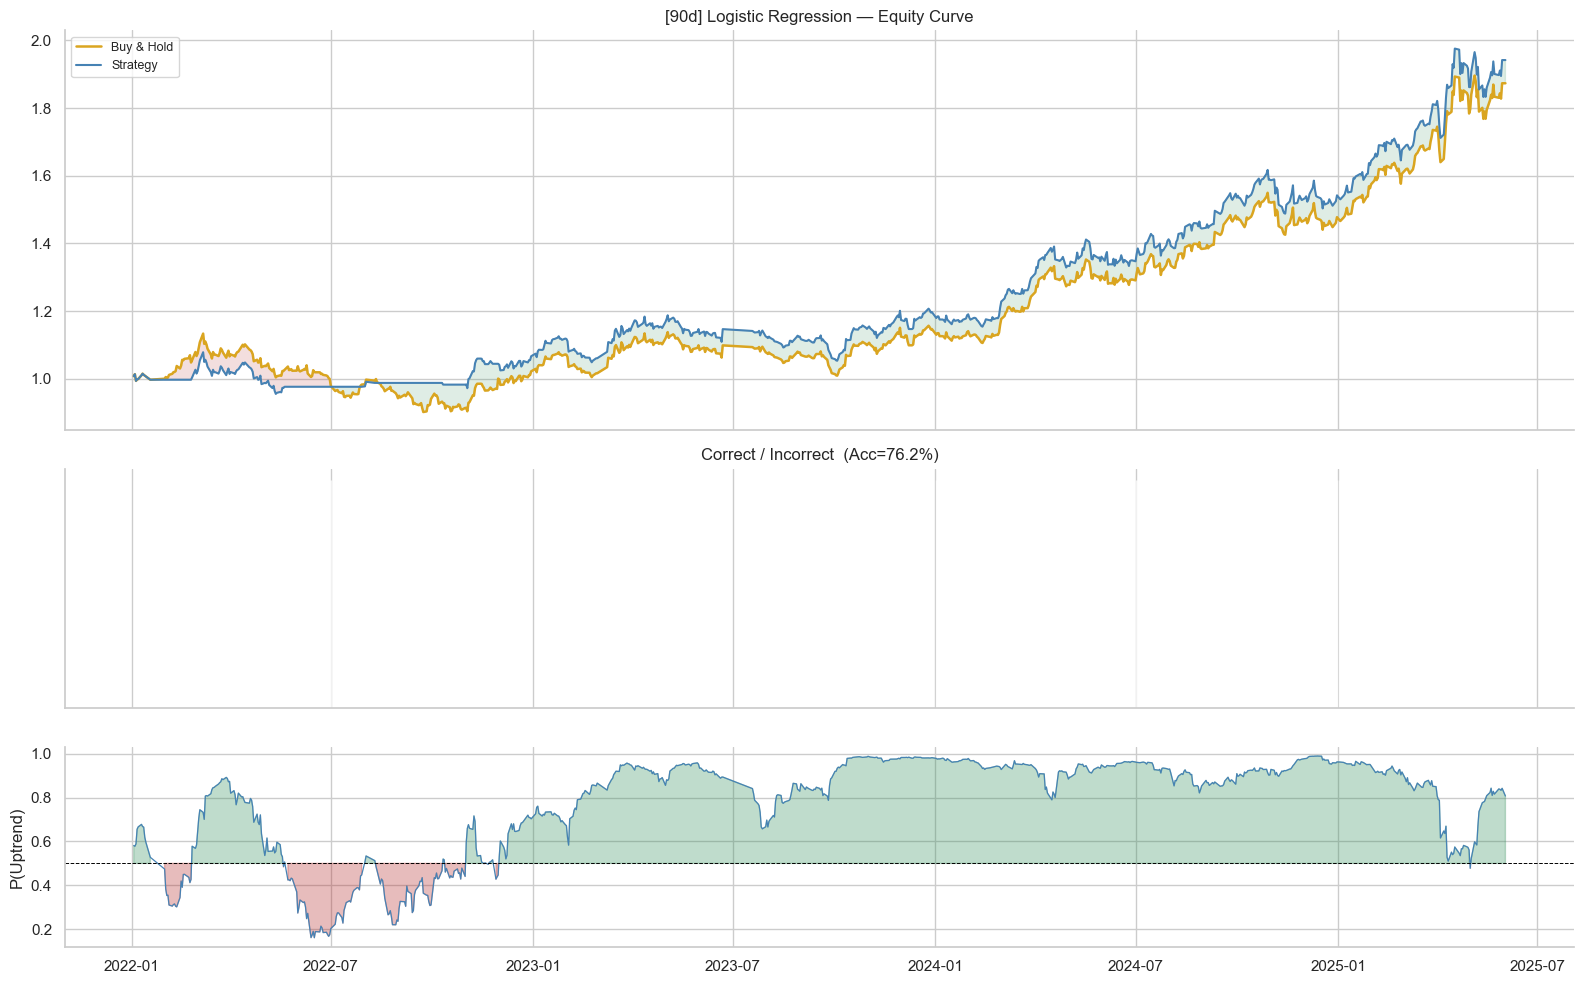

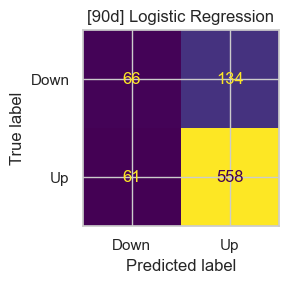


--- Logistic Regression | 252d ---
  Logistic Regression        | Acc= 97.7%  F1= 98.8%  AUC= 99.7%  Prec=100.0%  Rec= 97.6%


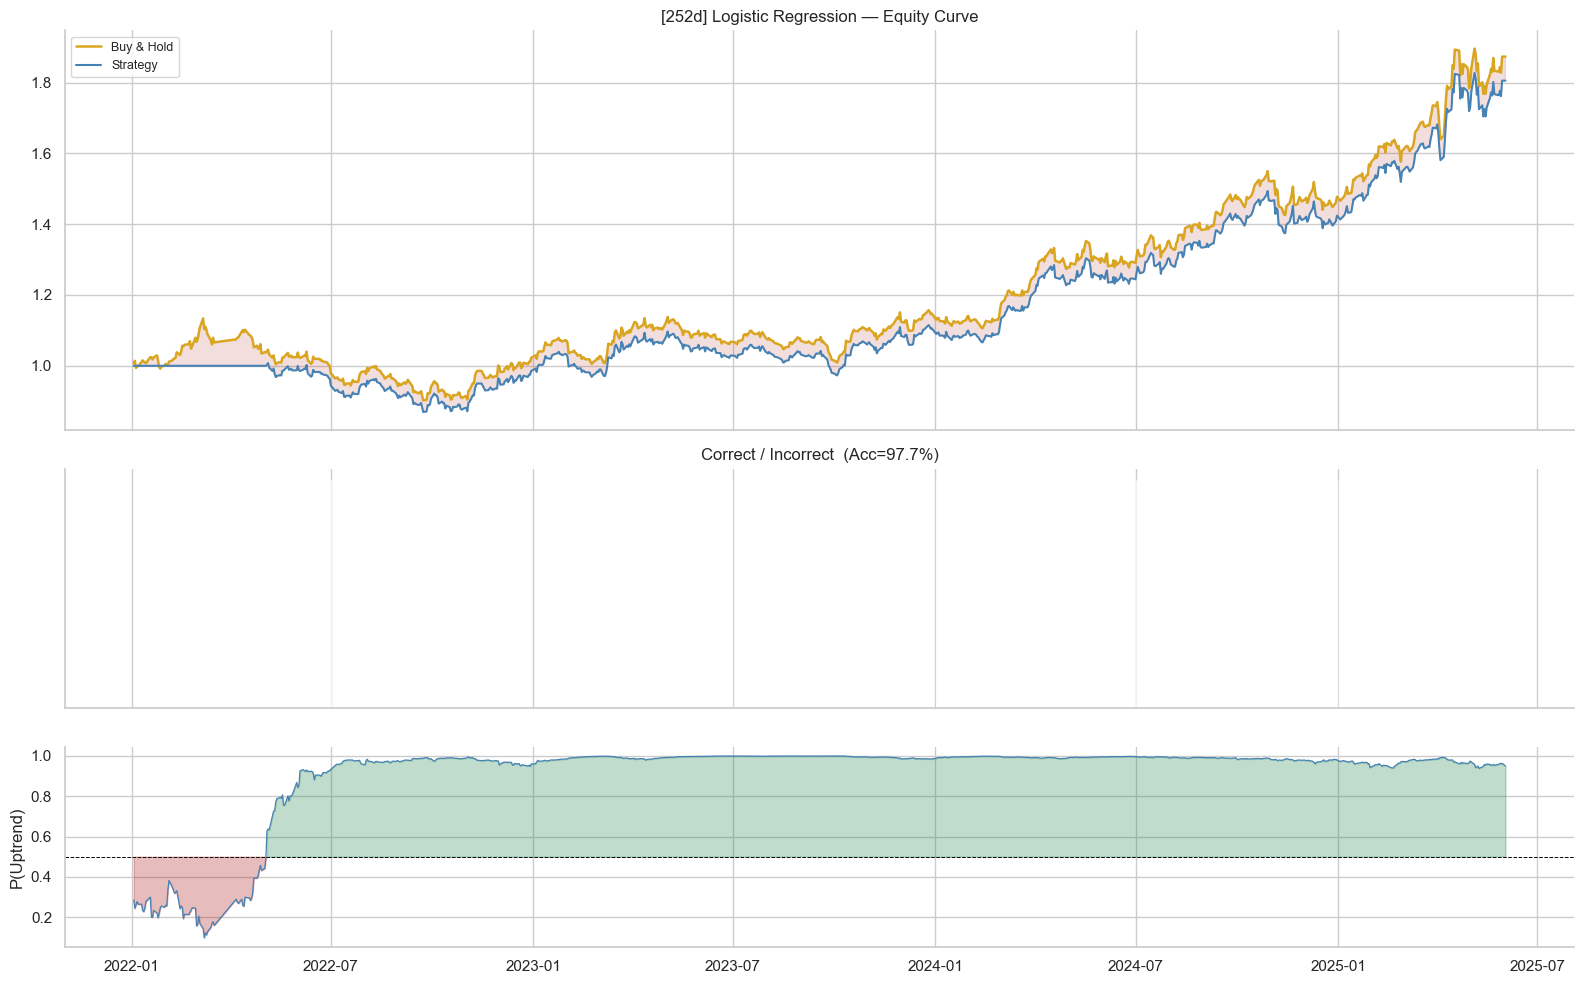

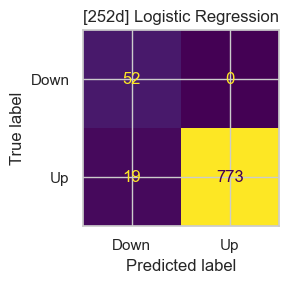

In [9]:
for HORIZON in [90, 252]:
    s = setup[HORIZON]
    print(f"\n--- Logistic Regression | {HORIZON}d ---")

    lr = LogisticRegression(C=0.01, max_iter=1000, random_state=42, class_weight="balanced")
    lr.fit(s["Xs_tr"], s["y_train"])

    pred = lr.predict(s["Xs_te"])
    prob = lr.predict_proba(s["Xs_te"])[:, 1]

    all_preds[HORIZON]["LR"]  = pred
    all_probs[HORIZON]["LR"]  = prob
    all_models[HORIZON]["LR"] = lr
    all_results[HORIZON].append(evaluate("Logistic Regression", s["y_test"], pred, prob))
    plot_equity("Logistic Regression", s["test_df"], s["y_test"], pred, prob, HORIZON)

### 4.2 Random Forest (90d & 252d)


--- Random Forest | 90d ---
  Random Forest              | Acc= 78.6%  F1= 86.5%  AUC= 71.4%  Prec= 82.7%  Rec= 90.6%


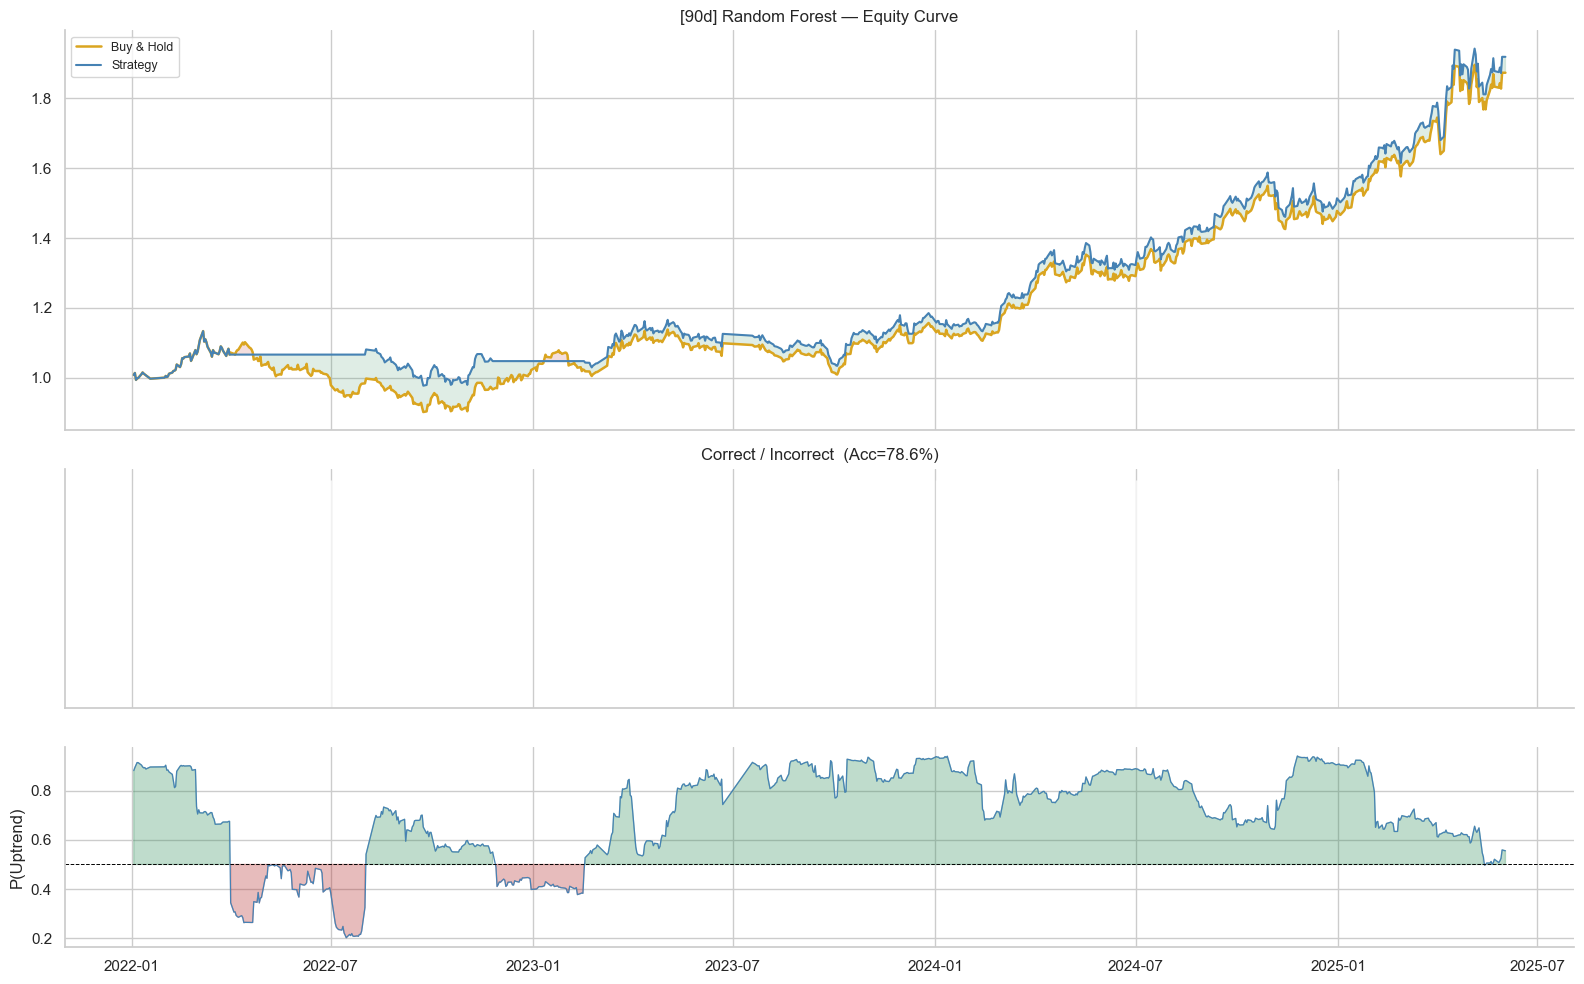

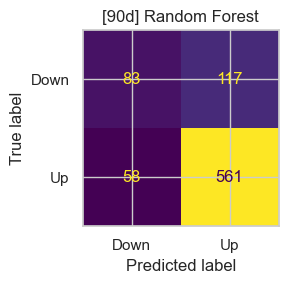


--- Random Forest | 252d ---
  Random Forest              | Acc= 94.1%  F1= 96.8%  AUC= 97.3%  Prec= 99.5%  Rec= 94.2%


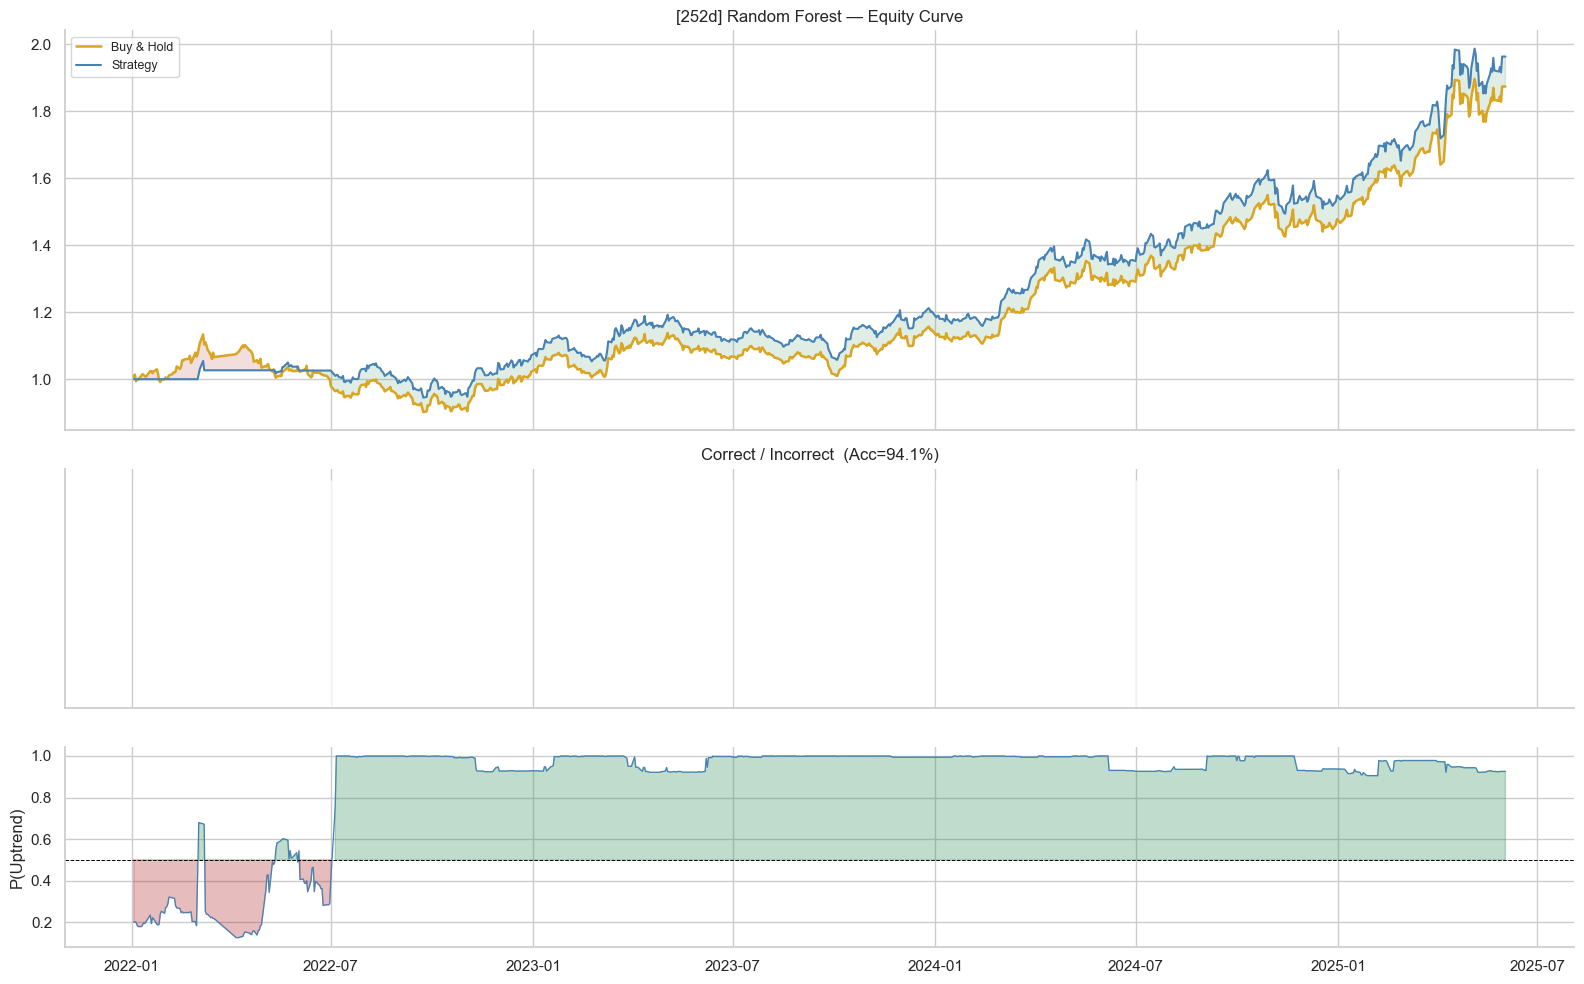

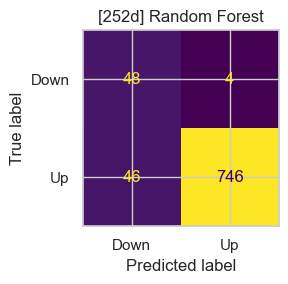

In [10]:
for HORIZON in [90, 252]:
    s = setup[HORIZON]
    print(f"\n--- Random Forest | {HORIZON}d ---")

    rf = RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=20,
        max_features=0.3, class_weight="balanced", n_jobs=-1, random_state=42,
    )
    rf.fit(s["X_tr"], s["y_train"], sample_weight=s["sw"])

    pred = rf.predict(s["X_te"])
    prob = rf.predict_proba(s["X_te"])[:, 1]

    all_preds[HORIZON]["RF"]  = pred
    all_probs[HORIZON]["RF"]  = prob
    all_models[HORIZON]["RF"] = rf
    all_results[HORIZON].append(evaluate("Random Forest", s["y_test"], pred, prob))
    plot_equity("Random Forest", s["test_df"], s["y_test"], pred, prob, HORIZON)

### 4.3 XGBoost + Optuna (90d & 252d)


--- XGBoost + Optuna | 90d ---


  0%|          | 0/60 [00:00<?, ?it/s]

  Best CV    : 0.5862
  Best params: {'n_estimators': 422, 'max_depth': 3, 'learning_rate': 0.014234695208527307, 'subsample': 0.6029148123346109, 'colsample_bytree': 0.5242100717712144, 'reg_alpha': 16.406224249006375, 'reg_lambda': 2.728486555750041, 'min_child_weight': 60, 'gamma': 3.1220259036281455}
  XGBoost                    | Acc= 72.9%  F1= 81.9%  AUC= 73.0%  Prec= 82.7%  Rec= 81.1%


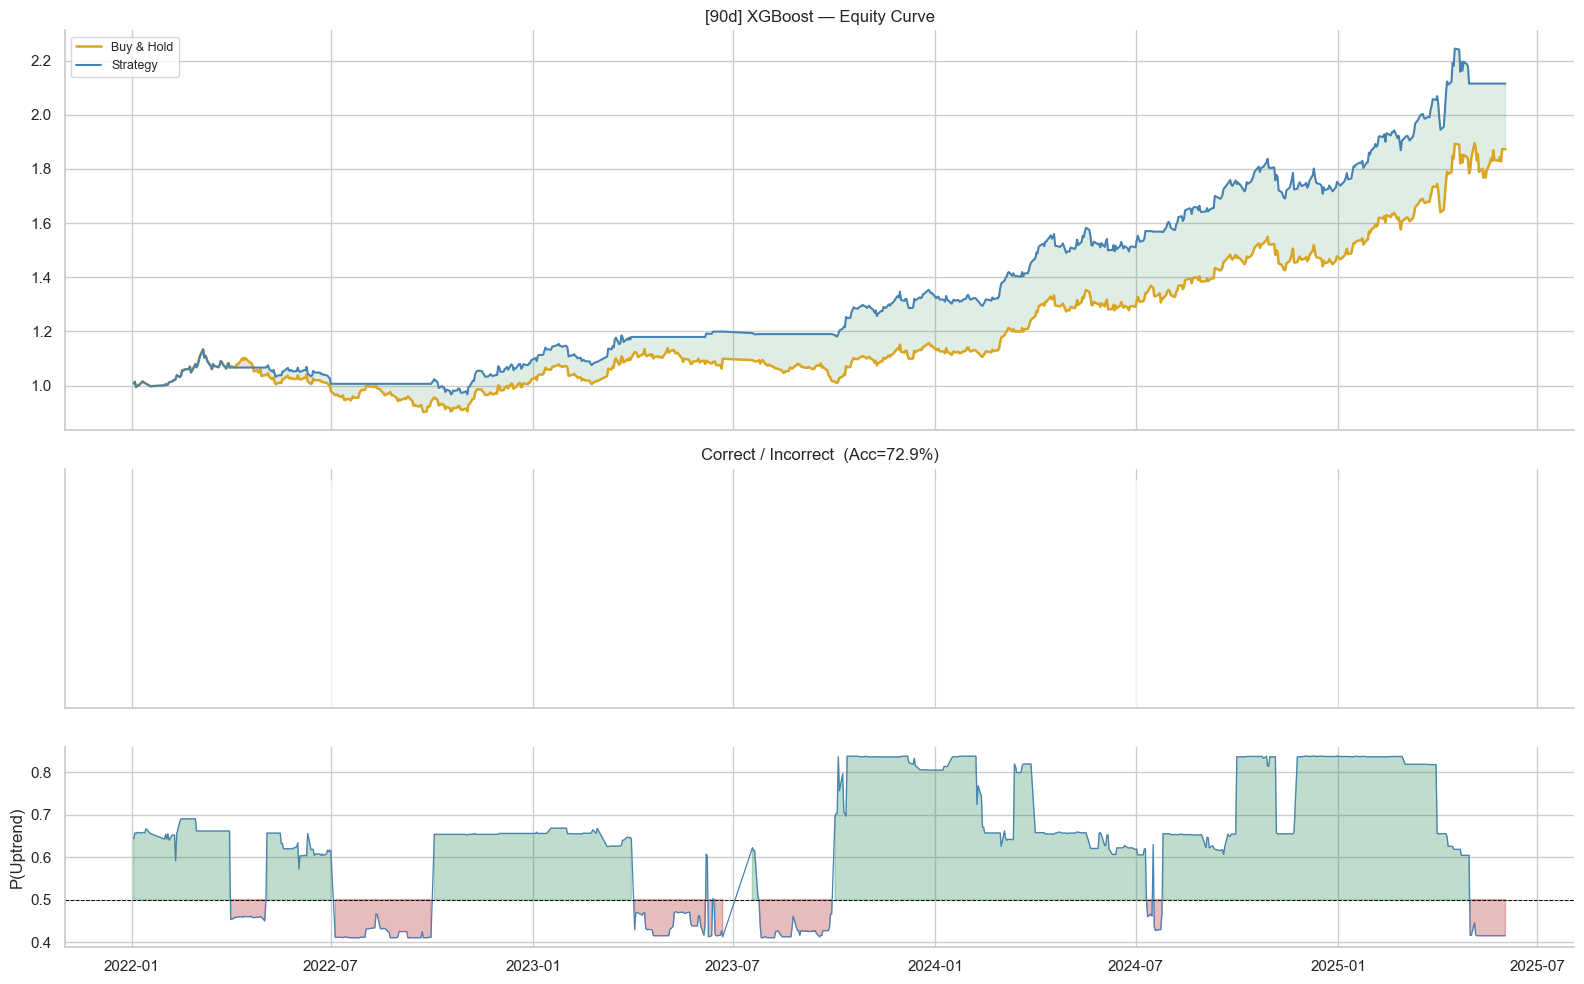

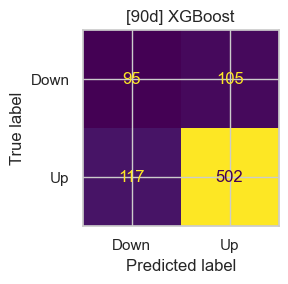


--- XGBoost + Optuna | 252d ---


  0%|          | 0/60 [00:00<?, ?it/s]

  Best CV    : 0.6157
  Best params: {'n_estimators': 192, 'max_depth': 2, 'learning_rate': 0.009380341222321733, 'subsample': 0.6520912881377339, 'colsample_bytree': 0.6053609135821184, 'reg_alpha': 4.987837577705995, 'reg_lambda': 7.941848380430207, 'min_child_weight': 28, 'gamma': 4.314300865357961}
  XGBoost                    | Acc= 93.4%  F1= 96.4%  AUC= 96.7%  Prec= 97.8%  Rec= 95.1%


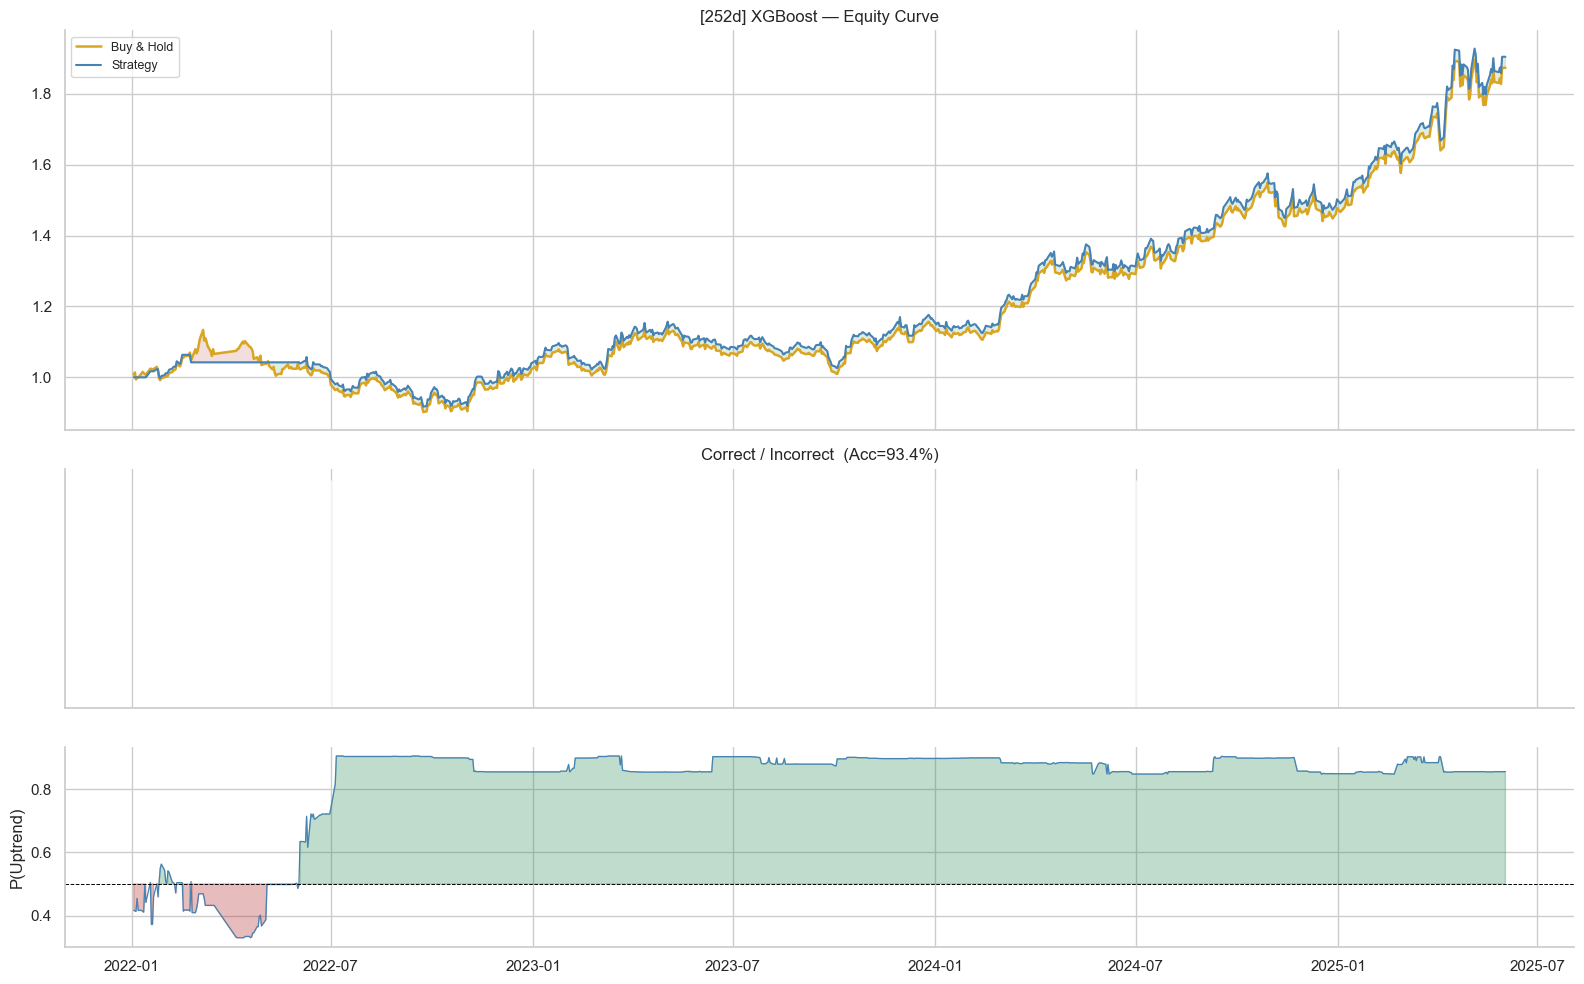

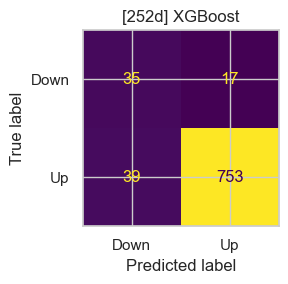

In [11]:
for HORIZON in [90, 252]:
    s = setup[HORIZON]
    print(f"\n--- XGBoost + Optuna | {HORIZON}d ---")

    def objective_xgb(trial):
        params = {
            "n_estimators":     trial.suggest_int("n_estimators", 100, 500),
            "max_depth":        trial.suggest_int("max_depth", 2, 4),
            "learning_rate":    trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
            "subsample":        trial.suggest_float("subsample", 0.5, 0.85),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 0.7),
            "reg_alpha":        trial.suggest_float("reg_alpha", 1.0, 30, log=True),
            "reg_lambda":       trial.suggest_float("reg_lambda", 1.0, 30, log=True),
            "min_child_weight": trial.suggest_int("min_child_weight", 20, 100),
            "gamma":            trial.suggest_float("gamma", 0.5, 5.0),
            "scale_pos_weight": s["spw"],
            "random_state": 42, "n_jobs": -1, "tree_method": "hist",
            "objective": "binary:logistic", "eval_metric": "auc",
        }
        cv_scores = []
        for tr_idx, va_idx in tscv.split(s["X_tr"]):
            m = XGBClassifier(**params)
            m.fit(s["X_tr"][tr_idx], s["y_train"][tr_idx],
                  sample_weight=s["sw"][tr_idx], verbose=False)
            prob = m.predict_proba(s["X_tr"][va_idx])[:, 1]
            hc   = (prob > 0.55) | (prob < 0.45)
            cv_scores.append(
                accuracy_score(s["y_train"][va_idx][hc], (prob[hc] > 0.5).astype(int))
                if hc.sum() >= 10 else 0.5
            )
        return np.mean(cv_scores)

    study_xgb = optuna.create_study(direction="maximize",
                                    sampler=optuna.samplers.TPESampler(seed=42))
    study_xgb.optimize(objective_xgb, n_trials=60, show_progress_bar=True)
    print(f"  Best CV    : {study_xgb.best_value:.4f}")
    print(f"  Best params: {study_xgb.best_params}")

    xgb = XGBClassifier(
        **study_xgb.best_params, scale_pos_weight=s["spw"],
        random_state=42, n_jobs=-1, tree_method="hist",
        objective="binary:logistic", eval_metric="auc",
    )
    xgb.fit(s["X_tr"], s["y_train"], sample_weight=s["sw"])

    pred = xgb.predict(s["X_te"])
    prob = xgb.predict_proba(s["X_te"])[:, 1]

    all_preds[HORIZON]["XGB"]   = pred
    all_probs[HORIZON]["XGB"]   = prob
    all_models[HORIZON]["XGB"]  = xgb
    all_studies[HORIZON]["xgb"] = study_xgb
    all_results[HORIZON].append(evaluate("XGBoost", s["y_test"], pred, prob))
    plot_equity("XGBoost", s["test_df"], s["y_test"], pred, prob, HORIZON)

### 4.4 LightGBM + Optuna (90d & 252d)


--- LightGBM + Optuna | 90d ---


  0%|          | 0/60 [00:00<?, ?it/s]

  Best CV    : 0.5407
  Best params: {'n_estimators': 424, 'num_leaves': 25, 'learning_rate': 0.03179429591032122, 'subsample': 0.6666124588995436, 'colsample_bytree': 0.6553911334887897, 'reg_alpha': 0.19931611823674283, 'reg_lambda': 0.10105819422830643, 'min_child_samples': 65}
  LightGBM                   | Acc= 76.1%  F1= 84.6%  AUC= 70.5%  Prec= 82.2%  Rec= 87.2%


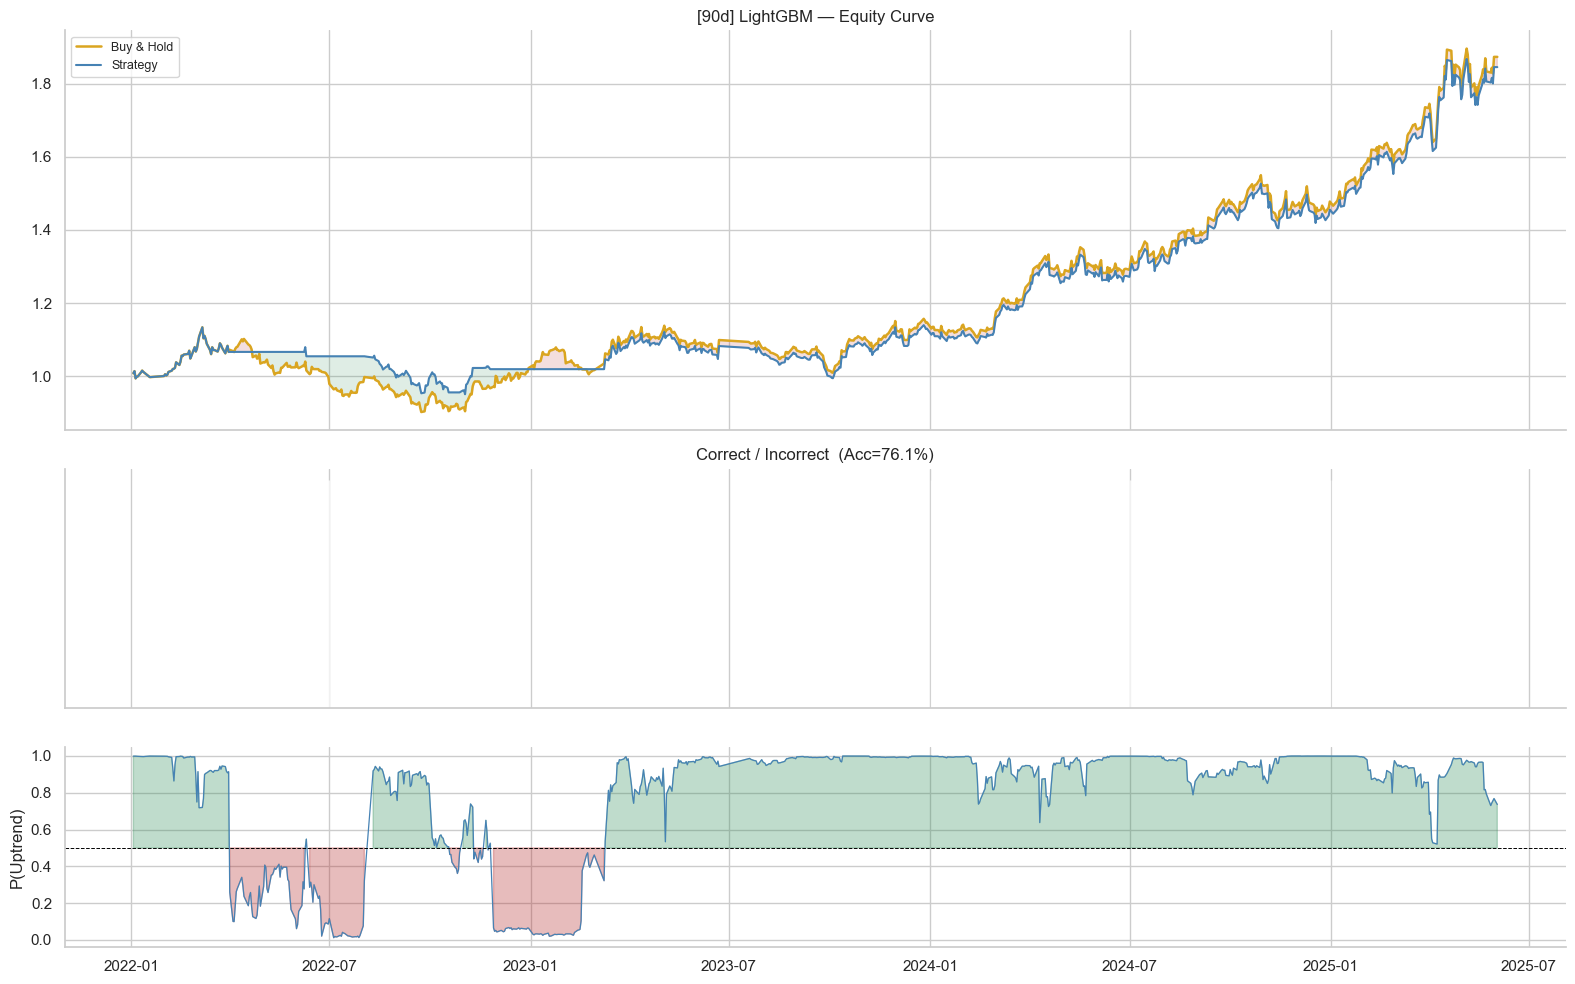

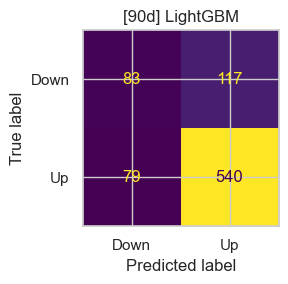


--- LightGBM + Optuna | 252d ---


  0%|          | 0/60 [00:00<?, ?it/s]

  Best CV    : 0.6891
  Best params: {'n_estimators': 168, 'num_leaves': 18, 'learning_rate': 0.00964726320204206, 'subsample': 0.6339838003323092, 'colsample_bytree': 0.6088247570772051, 'reg_alpha': 0.6553288901066281, 'reg_lambda': 0.15541907518519077, 'min_child_samples': 25}
  LightGBM                   | Acc= 97.4%  F1= 98.6%  AUC= 98.4%  Prec= 99.5%  Rec= 97.7%


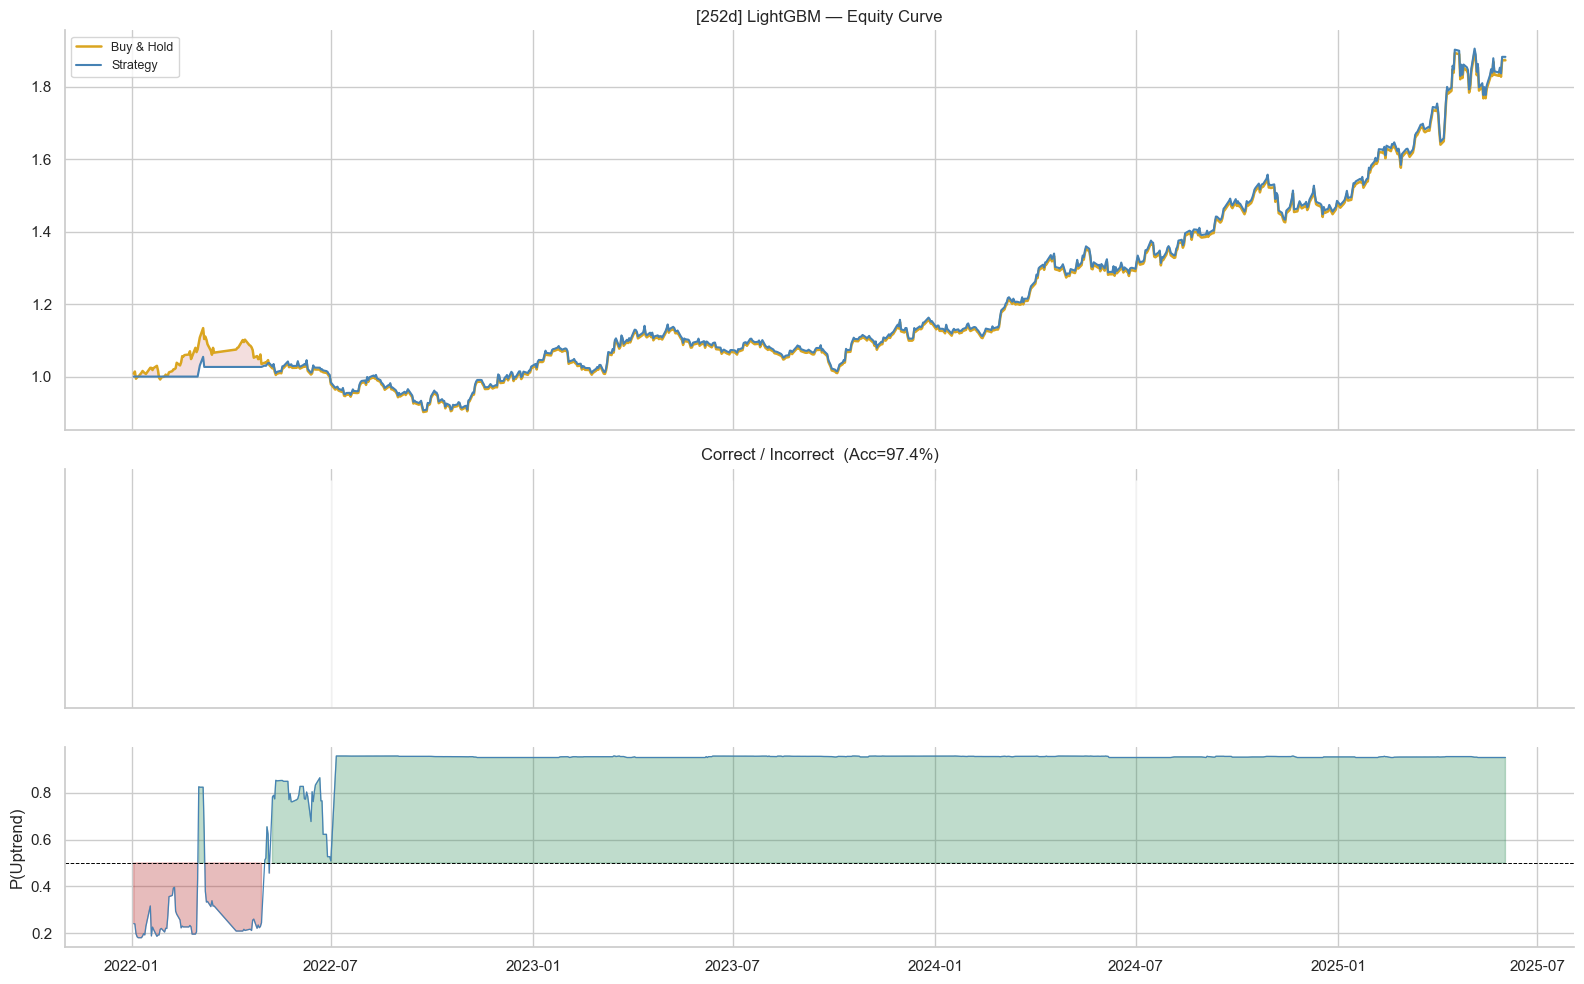

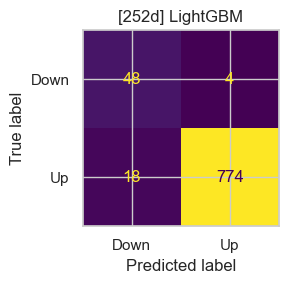

In [12]:
for HORIZON in [90, 252]:
    s = setup[HORIZON]
    print(f"\n--- LightGBM + Optuna | {HORIZON}d ---")

    def objective_lgbm(trial):
        params = {
            "n_estimators":      trial.suggest_int("n_estimators", 100, 500),
            "num_leaves":        trial.suggest_int("num_leaves", 8, 31),
            "learning_rate":     trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
            "subsample":         trial.suggest_float("subsample", 0.5, 0.85),
            "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.3, 0.7),
            "reg_alpha":         trial.suggest_float("reg_alpha", 0.1, 20, log=True),
            "reg_lambda":        trial.suggest_float("reg_lambda", 0.1, 20, log=True),
            "min_child_samples": trial.suggest_int("min_child_samples", 20, 100),
            "scale_pos_weight":  s["spw"],
            "random_state": 42, "n_jobs": -1, "verbose": -1,
        }
        cv_scores = []
        for tr_idx, va_idx in tscv.split(s["X_tr"]):
            m = LGBMClassifier(**params)
            m.fit(s["X_tr"][tr_idx], s["y_train"][tr_idx],
                  sample_weight=s["sw"][tr_idx])
            prob = m.predict_proba(s["X_tr"][va_idx])[:, 1]
            hc   = (prob > 0.55) | (prob < 0.45)
            cv_scores.append(
                accuracy_score(s["y_train"][va_idx][hc], (prob[hc] > 0.5).astype(int))
                if hc.sum() >= 10 else 0.5
            )
        return np.mean(cv_scores)

    study_lgbm = optuna.create_study(direction="maximize",
                                     sampler=optuna.samplers.TPESampler(seed=42))
    study_lgbm.optimize(objective_lgbm, n_trials=60, show_progress_bar=True)
    print(f"  Best CV    : {study_lgbm.best_value:.4f}")
    print(f"  Best params: {study_lgbm.best_params}")

    lgbm = LGBMClassifier(
        **study_lgbm.best_params, scale_pos_weight=s["spw"],
        random_state=42, n_jobs=-1, verbose=-1,
    )
    lgbm.fit(s["X_tr"], s["y_train"], sample_weight=s["sw"])

    pred = lgbm.predict(s["X_te"])
    prob = lgbm.predict_proba(s["X_te"])[:, 1]

    all_preds[HORIZON]["LGBM"]   = pred
    all_probs[HORIZON]["LGBM"]   = prob
    all_models[HORIZON]["LGBM"]  = lgbm
    all_studies[HORIZON]["lgbm"] = study_lgbm
    all_results[HORIZON].append(evaluate("LightGBM", s["y_test"], pred, prob))
    plot_equity("LightGBM", s["test_df"], s["y_test"], pred, prob, HORIZON)

### 4.5 Ensemble: Soft Voting (90d & 252d)


--- Soft Voting | 90d ---
  Soft Voting                | Acc= 78.0%  F1= 86.2%  AUC= 76.9%  Prec= 81.9%  Rec= 91.1%


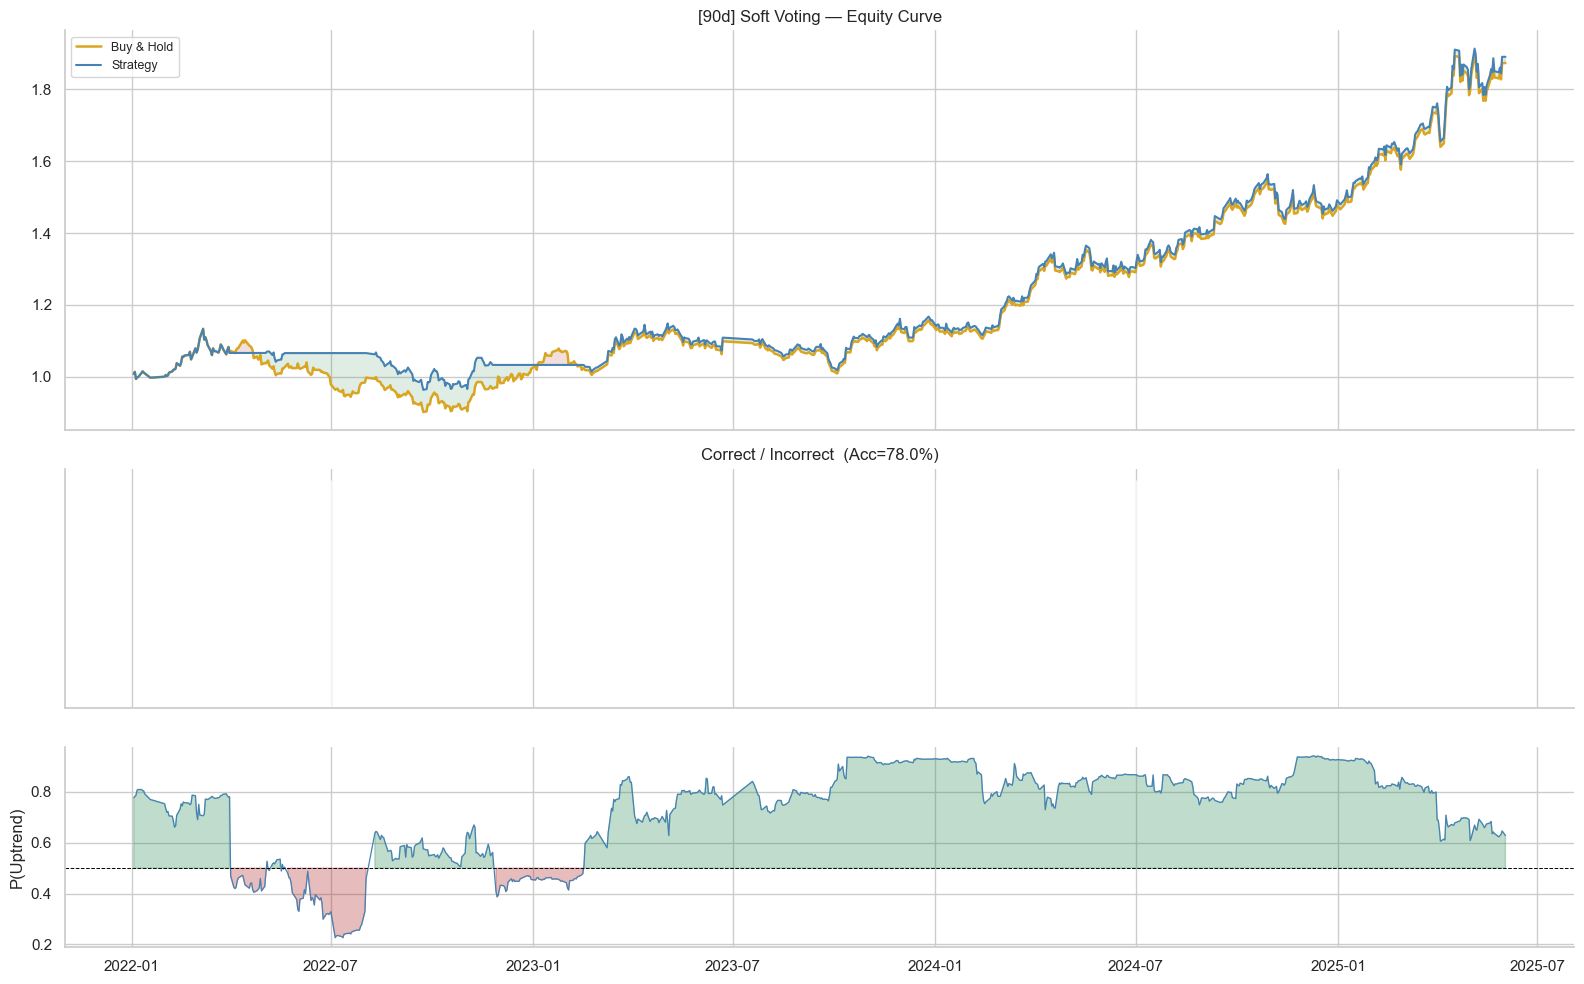

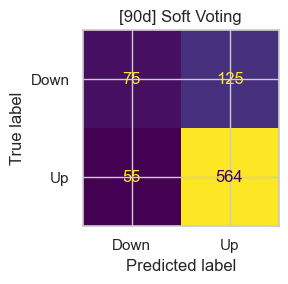


--- Soft Voting | 252d ---
  Soft Voting                | Acc= 97.3%  F1= 98.5%  AUC= 98.3%  Prec= 99.6%  Rec= 97.5%


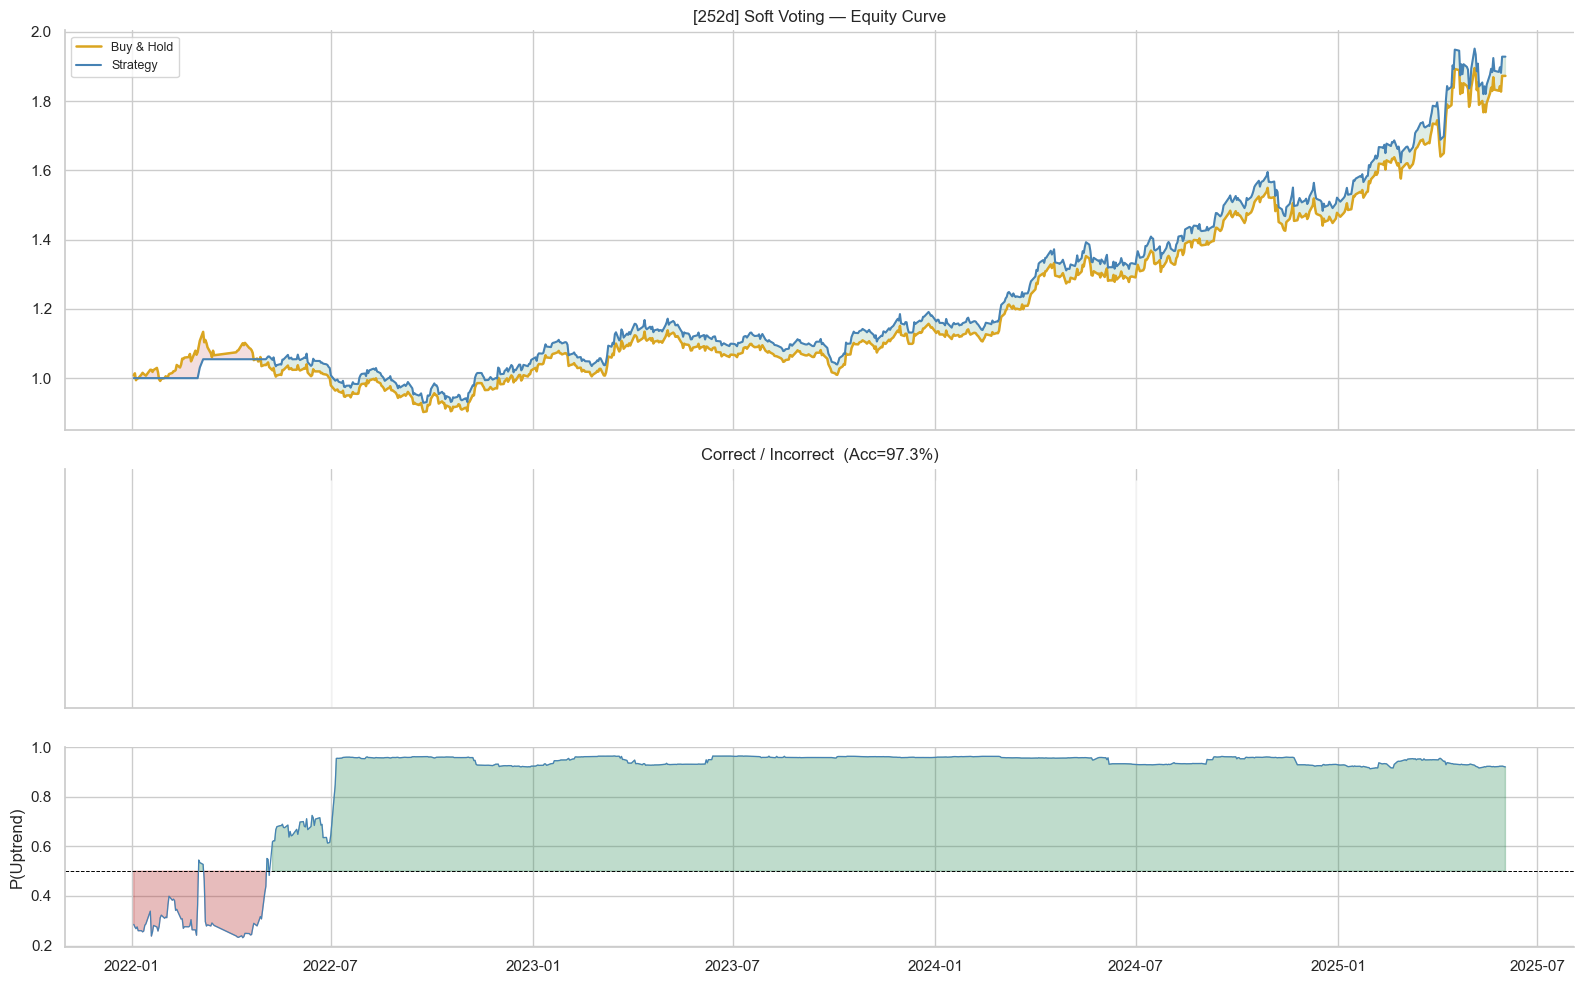

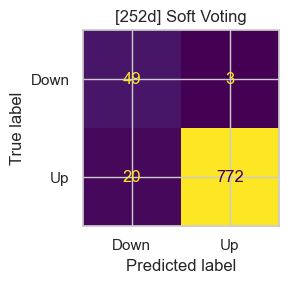

In [13]:
for HORIZON in [90, 252]:
    s = setup[HORIZON]
    print(f"\n--- Soft Voting | {HORIZON}d ---")

    prob_soft = (all_probs[HORIZON]["LR"]  + all_probs[HORIZON]["RF"] +
                 all_probs[HORIZON]["XGB"] + all_probs[HORIZON]["LGBM"]) / 4
    pred_soft = (prob_soft >= 0.5).astype(int)

    all_probs[HORIZON]["SoftVote"] = prob_soft
    all_preds[HORIZON]["SoftVote"] = pred_soft
    all_results[HORIZON].append(evaluate("Soft Voting", s["y_test"], pred_soft, prob_soft))
    plot_equity("Soft Voting", s["test_df"], s["y_test"], pred_soft, prob_soft, HORIZON)

### 4.6 Ensemble: Weighted Voting (90d & 252d)


--- Weighted Voting | 90d ---
  Weights -> LR=0.227  RF=0.273  XGB=0.220  LGBM=0.280
  Weighted Voting            | Acc= 78.0%  F1= 86.2%  AUC= 76.6%  Prec= 82.0%  Rec= 91.0%


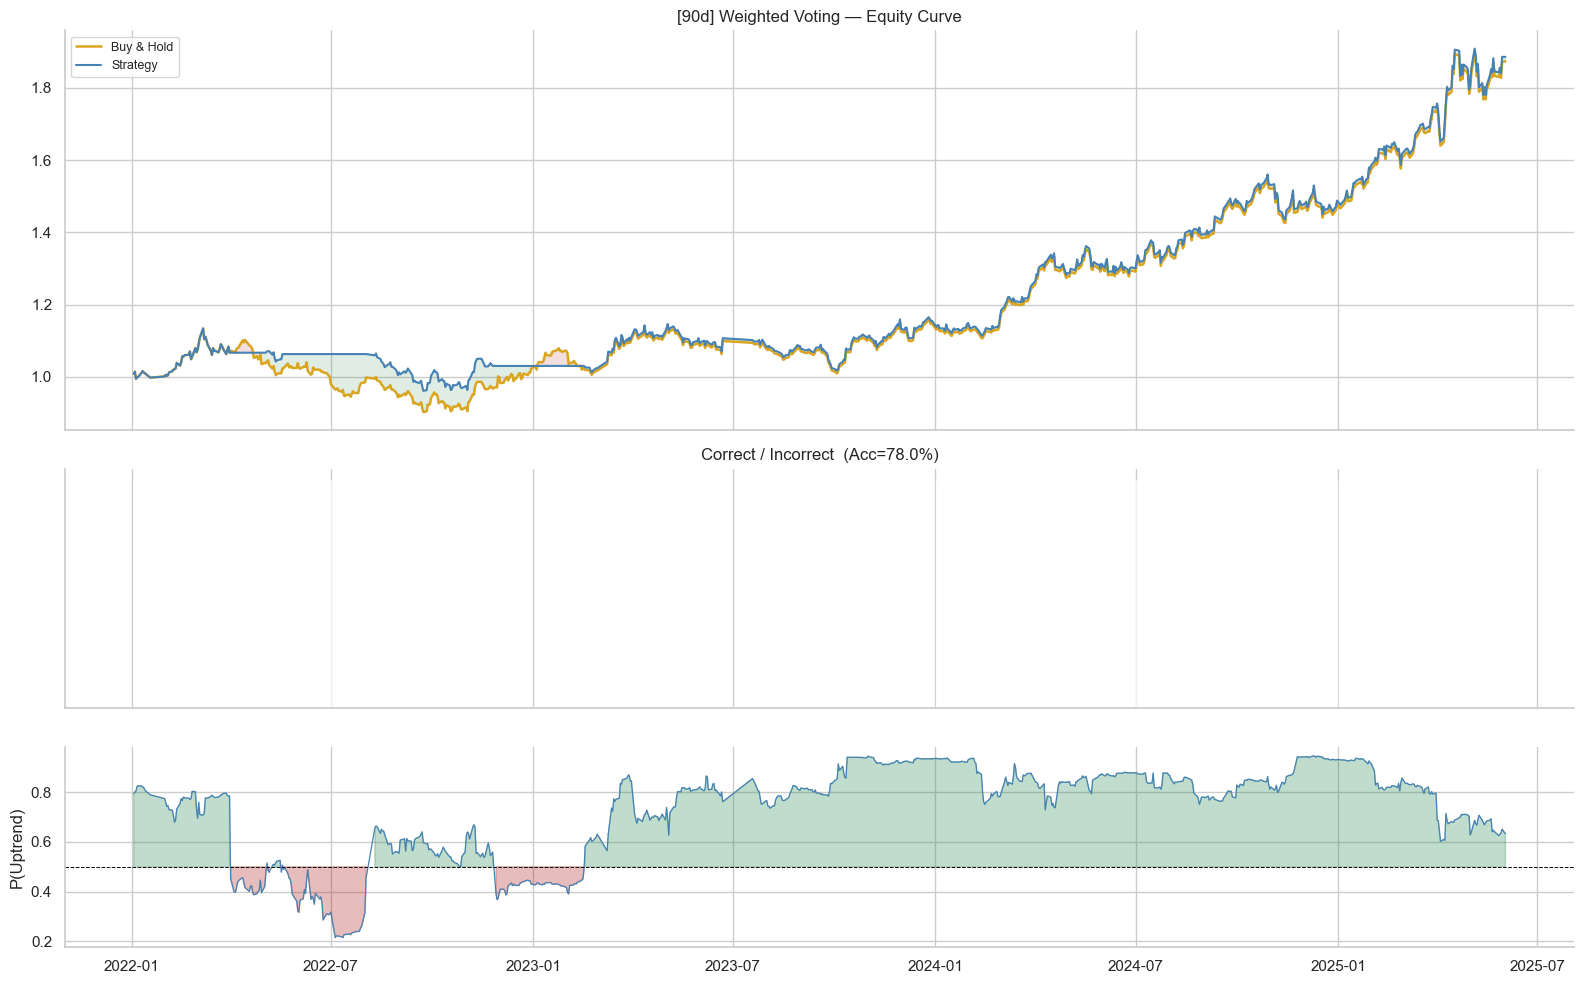

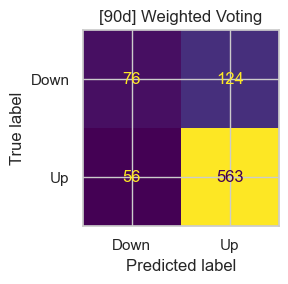


--- Weighted Voting | 252d ---
  Weights -> LR=0.227  RF=0.264  XGB=0.245  LGBM=0.265
  Weighted Voting            | Acc= 97.3%  F1= 98.5%  AUC= 98.2%  Prec= 99.6%  Rec= 97.5%


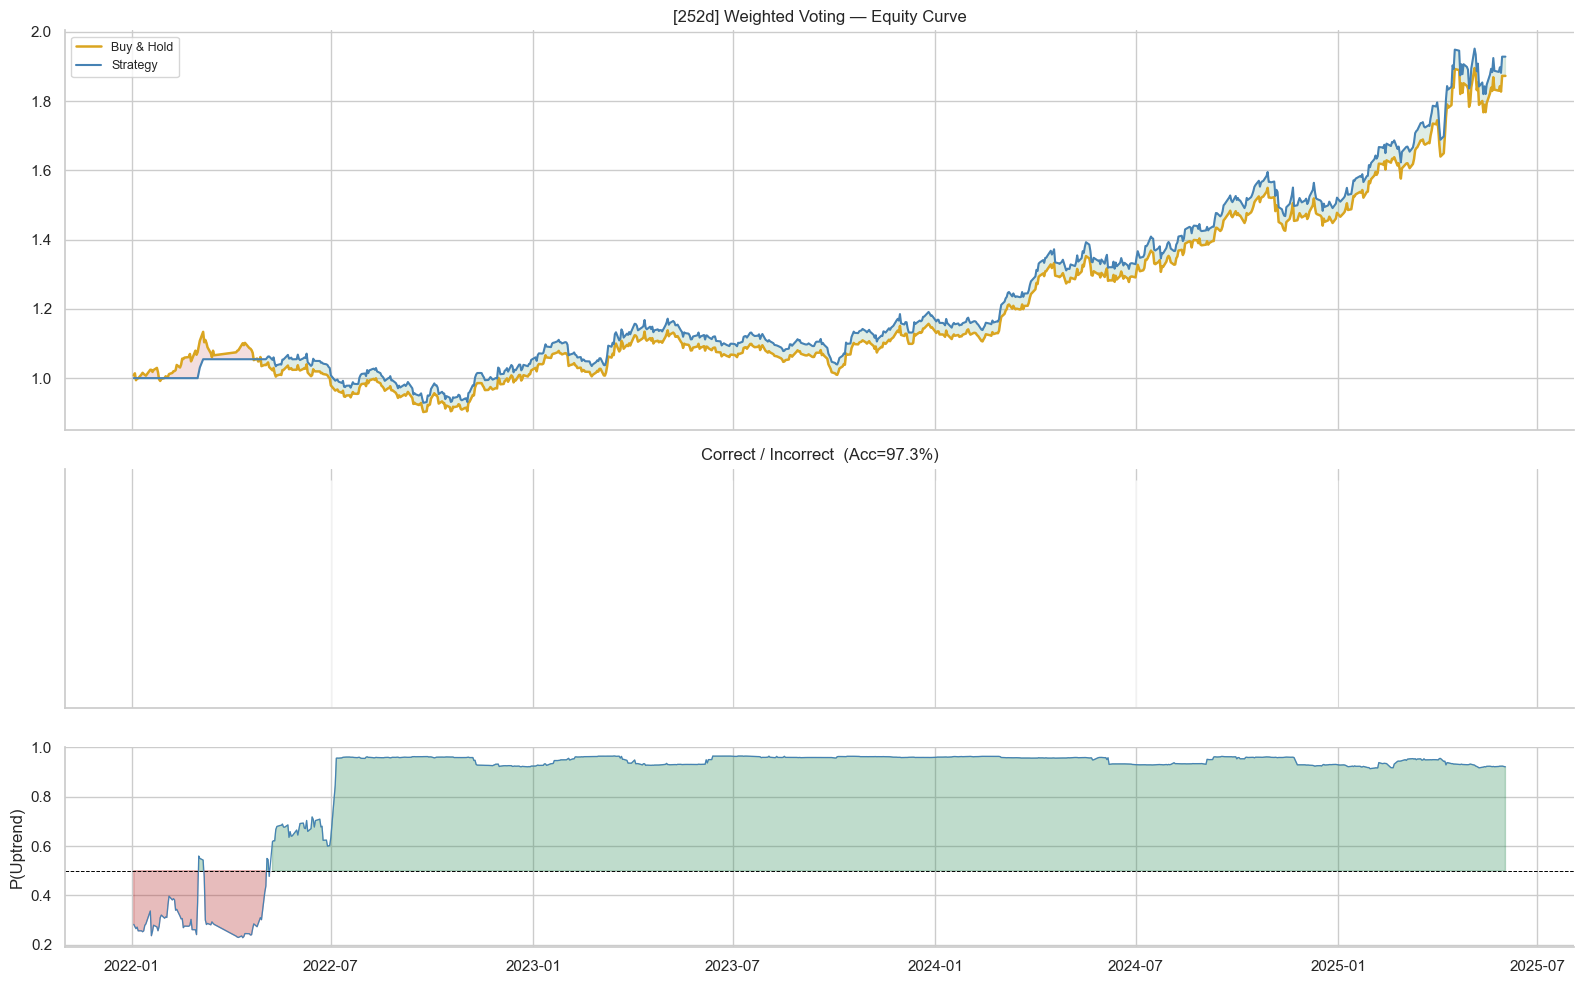

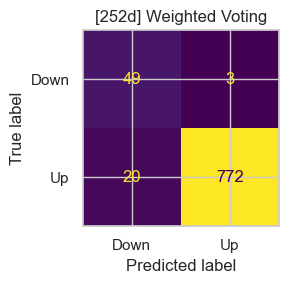

In [14]:
for HORIZON in [90, 252]:
    s = setup[HORIZON]
    print(f"\n--- Weighted Voting | {HORIZON}d ---")

    lr   = all_models[HORIZON]["LR"]
    rf   = all_models[HORIZON]["RF"]
    xgb  = all_models[HORIZON]["XGB"]
    lgbm = all_models[HORIZON]["LGBM"]

    train_aucs = {
        "LR":   roc_auc_score(s["y_train"], lr.predict_proba(s["Xs_tr"])[:,1]),
        "RF":   roc_auc_score(s["y_train"], rf.predict_proba(s["X_tr"])[:,1]),
        "XGB":  roc_auc_score(s["y_train"], xgb.predict_proba(s["X_tr"])[:,1]),
        "LGBM": roc_auc_score(s["y_train"], lgbm.predict_proba(s["X_tr"])[:,1]),
    }
    w = np.array([train_aucs[k] for k in ["LR","RF","XGB","LGBM"]])
    w = w / w.sum()

    print(f"  Weights -> " + "  ".join(f"{k}={wi:.3f}" for k, wi in zip(["LR","RF","XGB","LGBM"], w)))

    prob_wv = (w[0]*all_probs[HORIZON]["LR"]  + w[1]*all_probs[HORIZON]["RF"] +
               w[2]*all_probs[HORIZON]["XGB"] + w[3]*all_probs[HORIZON]["LGBM"])
    pred_wv = (prob_wv >= 0.5).astype(int)

    all_probs[HORIZON]["WeightedVote"] = prob_wv
    all_preds[HORIZON]["WeightedVote"] = pred_wv
    all_results[HORIZON].append(evaluate("Weighted Voting", s["y_test"], pred_wv, prob_wv))
    plot_equity("Weighted Voting", s["test_df"], s["y_test"], pred_wv, prob_wv, HORIZON)

### 4.7 Ensemble: Stacking (90d & 252d)


--- Stacking | 90d ---
  Meta coef -> LR=-0.868  RF=-4.119  XGB=3.747  LGBM=2.137
  Stacking                   | Acc= 72.3%  F1= 83.1%  AUC= 56.4%  Prec= 77.0%  Rec= 90.3%


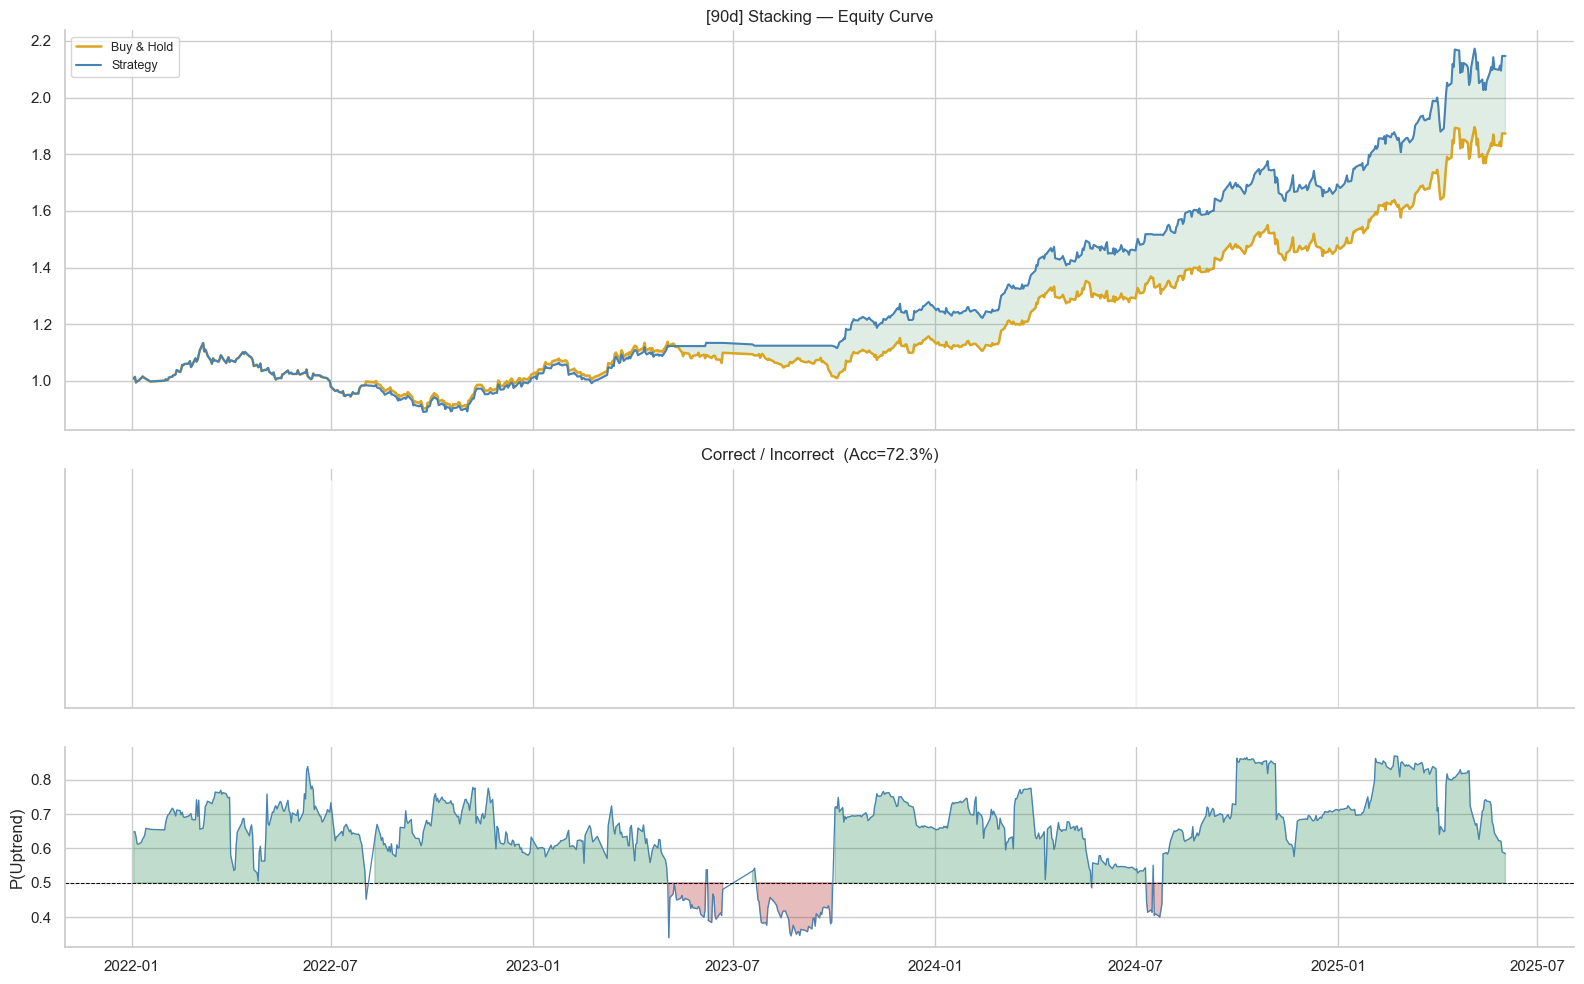

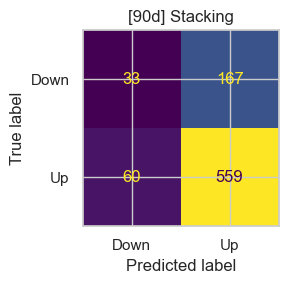


--- Stacking | 252d ---
  Meta coef -> LR=-2.116  RF=1.801  XGB=-1.303  LGBM=0.830
  Stacking                   | Acc= 91.0%  F1= 95.3%  AUC=  4.1%  Prec= 93.7%  Rec= 97.0%


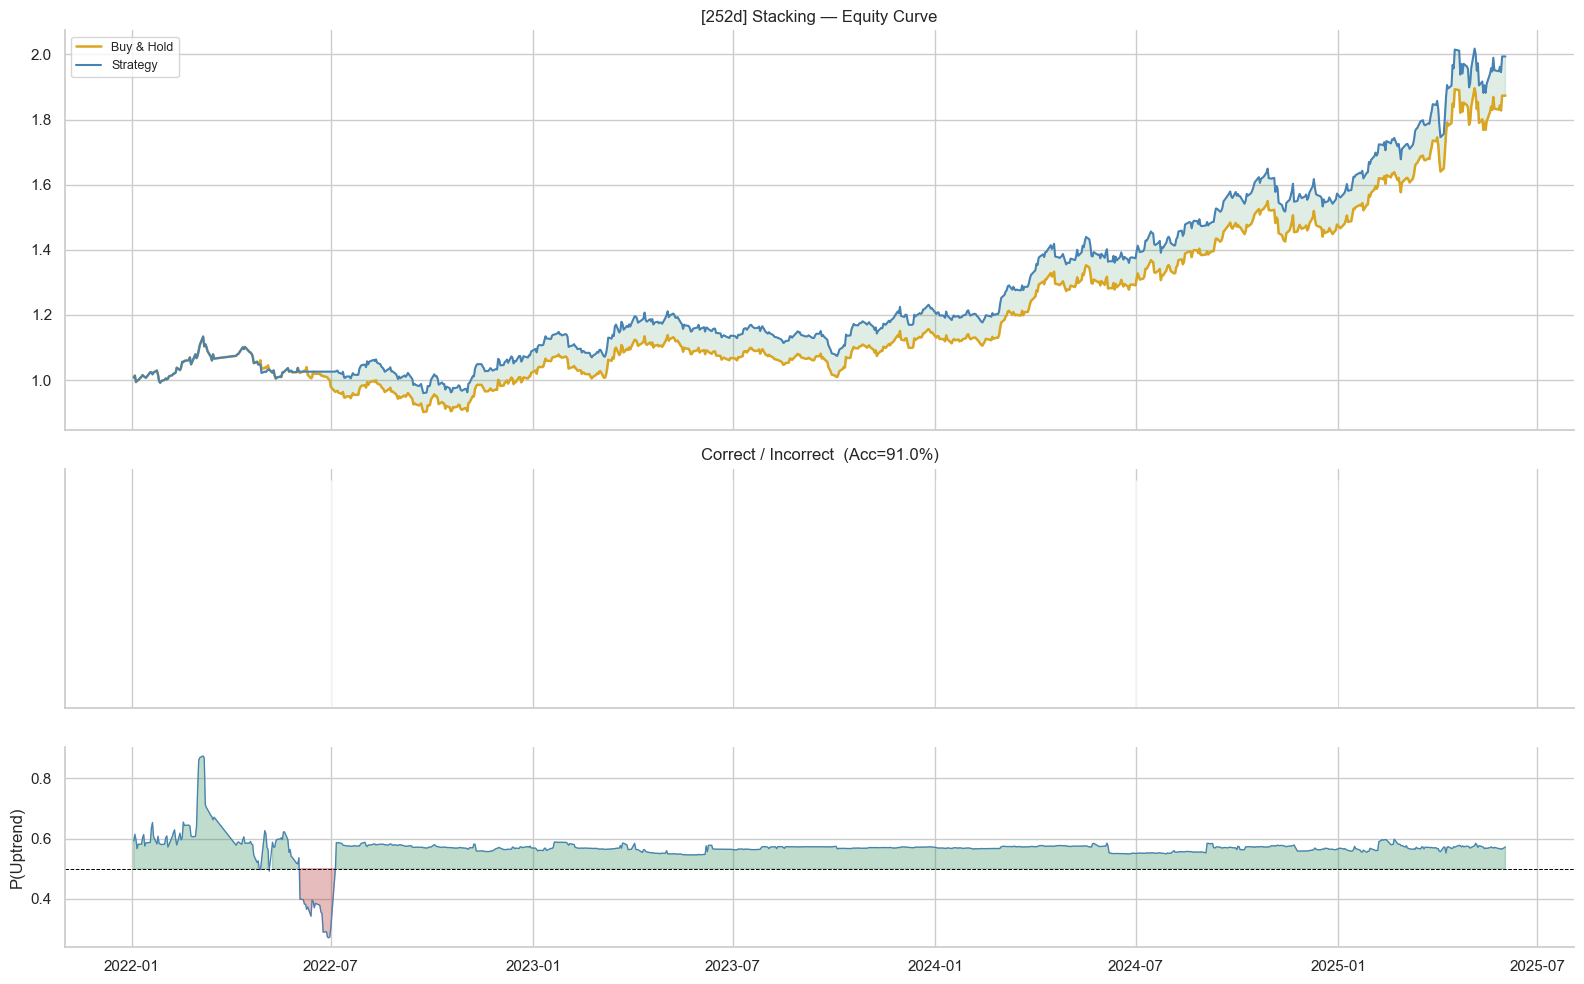

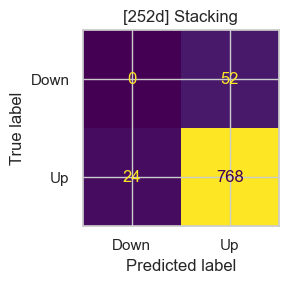

In [15]:
for HORIZON in [90, 252]:
    s = setup[HORIZON]
    print(f"\n--- Stacking | {HORIZON}d ---")

    lr   = all_models[HORIZON]["LR"]
    rf   = all_models[HORIZON]["RF"]
    xgb  = all_models[HORIZON]["XGB"]
    lgbm = all_models[HORIZON]["LGBM"]

    oof      = np.zeros((len(s["X_tr"]), 4))
    tscv_stk = TimeSeriesSplit(n_splits=5)
    base_cfg = [("LR", lr, True), ("RF", rf, False),
                ("XGB", xgb, False), ("LGBM", lgbm, False)]

    for tr_idx, va_idx in tscv_stk.split(s["X_tr"]):
        for m_idx, (mname, mobj, scaled) in enumerate(base_cfg):
            Xtr_ = s["Xs_tr"][tr_idx] if scaled else s["X_tr"][tr_idx]
            Xva_ = s["Xs_tr"][va_idx] if scaled else s["X_tr"][va_idx]
            sw_  = s["sw"][tr_idx]
            if scaled:
                mobj.fit(Xtr_, s["y_train"][tr_idx])
            else:
                mobj.fit(Xtr_, s["y_train"][tr_idx], sample_weight=sw_)
            oof[va_idx, m_idx] = mobj.predict_proba(Xva_)[:, 1]

    meta     = LogisticRegression(C=1.0, random_state=42)
    meta.fit(oof, s["y_train"])
    base_te  = np.column_stack([all_probs[HORIZON]["LR"],  all_probs[HORIZON]["RF"],
                                 all_probs[HORIZON]["XGB"], all_probs[HORIZON]["LGBM"]])
    prob_stk = meta.predict_proba(base_te)[:, 1]
    pred_stk = (prob_stk >= 0.5).astype(int)

    print(f"  Meta coef -> " + "  ".join(
        f"{k}={v:.3f}" for k, v in zip(["LR","RF","XGB","LGBM"], meta.coef_[0])))

    all_probs[HORIZON]["Stack"] = prob_stk
    all_preds[HORIZON]["Stack"] = pred_stk
    all_results[HORIZON].append(evaluate("Stacking", s["y_test"], pred_stk, prob_stk))
    plot_equity("Stacking", s["test_df"], s["y_test"], pred_stk, prob_stk, HORIZON)

# Convert list -> DataFrame
for HORIZON in [90, 252]:
    all_results[HORIZON] = pd.DataFrame(all_results[HORIZON]).set_index("model")

## 5. Results Summary

In [16]:
for HORIZON in [90, 252]:
    best = all_results[HORIZON]["auc"].idxmax()
    print(f"\n{'='*55}")
    print(f"  Horizon {HORIZON}d — Results")
    print(f"{'='*55}")
    print(all_results[HORIZON].round(2).to_string())
    print(f"\n  Best model (AUC): {best} -> {all_results[HORIZON].loc[best,'auc']:.1f}%")


  Horizon 90d — Results
                     accuracy     f1    auc  prec_up  recall_up
model                                                          
Logistic Regression     76.19  85.13  68.10    80.64      90.15
Random Forest           78.63  86.51  71.36    82.74      90.63
XGBoost                 72.89  81.89  73.04    82.70      81.10
LightGBM                76.07  84.64  70.46    82.19      87.24
Soft Voting             78.02  86.24  76.93    81.86      91.11
Weighted Voting         78.02  86.22  76.57    81.95      90.95
Stacking                72.28  83.12  56.39    77.00      90.31

  Best model (AUC): Soft Voting -> 76.9%

  Horizon 252d — Results
                     accuracy     f1    auc  prec_up  recall_up
model                                                          
Logistic Regression     97.75  98.79  99.73   100.00      97.60
Random Forest           94.08  96.76  97.33    99.47      94.19
XGBoost                 93.36  96.41  96.71    97.79      95.08
LightGBM   

## 6. So sánh 90d vs 252d

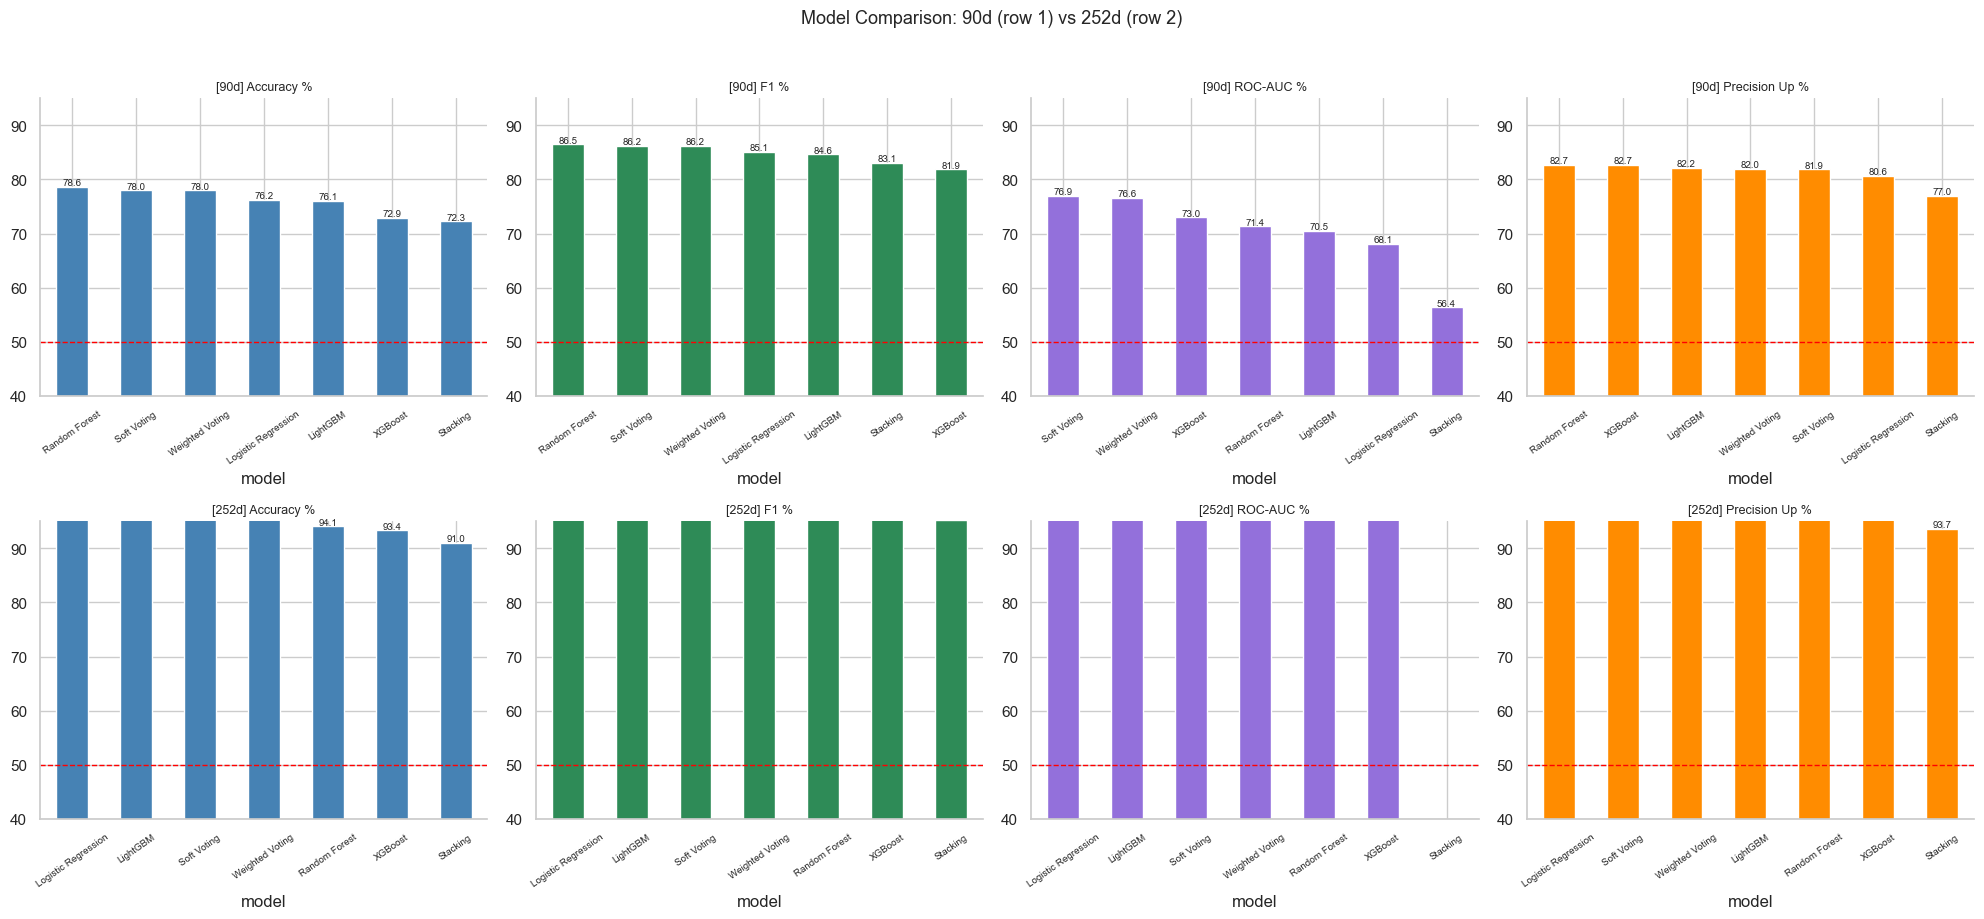

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
metrics = [("accuracy","Accuracy %"), ("f1","F1 %"),
           ("auc","ROC-AUC %"), ("prec_up","Precision Up %")]
colors  = ["steelblue", "seagreen", "mediumpurple", "darkorange"]

for row_idx, (h, cfg) in enumerate(HORIZON_CONFIG.items()):
    df_res = all_results[h]
    for col_idx, ((metric, title), color) in enumerate(zip(metrics, colors)):
        ax = axes[row_idx, col_idx]
        df_res[metric].sort_values(ascending=False).plot(
            kind="bar", ax=ax, color=color, edgecolor="white", rot=35)
        ax.set_title(f"[{h}d] {title}", fontsize=9)
        ax.axhline(50, color="red", linestyle="--", linewidth=1)
        ax.set_ylim(40, 95)
        ax.spines[["top","right"]].set_visible(False)
        ax.tick_params(axis="x", labelsize=7)
        for p in ax.patches:
            ax.annotate(f"{p.get_height():.1f}",
                        (p.get_x()+p.get_width()/2, p.get_height()+0.3),
                        ha="center", fontsize=7)

plt.suptitle("Model Comparison: 90d (row 1) vs 252d (row 2)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 7. Walk-Forward Validation (90d & 252d)


--- Walk-Forward | 90d ---
  Acc=65.4%  F1=75.1%  AUC=70.3%  Periods=29  Samples=1863

--- Walk-Forward | 252d ---
  Acc=72.7%  F1=83.8%  AUC=79.3%  Periods=29  Samples=1871


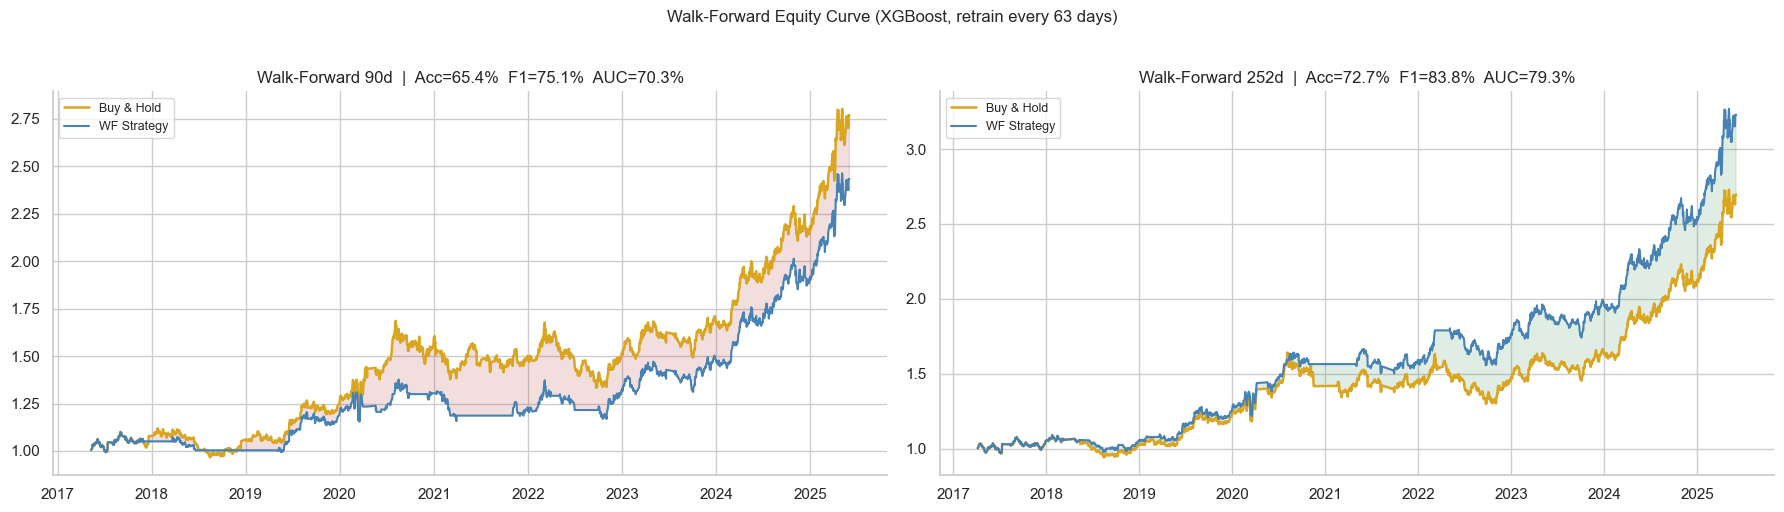

In [20]:
RETRAIN_FREQ = 63
MIN_TRAIN    = 500

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

for ax, (HORIZON, cfg) in zip(axes, HORIZON_CONFIG.items()):
    print(f"\n--- Walk-Forward | {HORIZON}d ---")

    TARGET_COL  = f"target_{HORIZON}d"
    SLOPE_COL   = f"slope_{HORIZON}d"
    study_xgb   = all_studies[HORIZON]["xgb"]
    s           = setup[HORIZON]

    df_model    = df_feat.dropna(subset=ALL_FEATURE_COLS + [TARGET_COL, SLOPE_COL]).copy()
    feat_sel_wf = s["feat_sel"]

    wf_preds, wf_probs, wf_dates, wf_true = [], [], [], []

    for start in range(MIN_TRAIN, len(df_model)-1, RETRAIN_FREQ):
        wf_tr = df_model.iloc[:start]
        wf_te = df_model.iloc[start:start+RETRAIN_FREQ]
        if len(wf_te) == 0:
            continue
        Xw   = wf_tr[feat_sel_wf].values
        yw   = wf_tr[TARGET_COL].values.astype(int)
        Xwt  = wf_te[feat_sel_wf].values
        ywt  = wf_te[TARGET_COL].values.astype(int)
        asl  = wf_tr[SLOPE_COL].abs()
        wfsw = (asl / asl.mean()).clip(
                   upper=np.percentile(asl / asl.mean(), 95)).values
        m = XGBClassifier(
            **study_xgb.best_params,
            scale_pos_weight=(yw==0).sum() / max((yw==1).sum(), 1),
            random_state=42, n_jobs=-1, tree_method="hist",
            objective="binary:logistic", eval_metric="auc",
        )
        m.fit(Xw, yw, sample_weight=wfsw)
        wf_preds.extend(m.predict(Xwt))
        wf_probs.extend(m.predict_proba(Xwt)[:, 1])
        wf_dates.extend(wf_te["date"].values)
        wf_true.extend(ywt)

    wf_df = pd.DataFrame({"date": wf_dates, "y_true": wf_true,
                           "y_pred": wf_preds, "y_prob": wf_probs})
    wf_df = wf_df.merge(df_model[["date","gold"]], on="date", how="left")
    wf_df["actual_ret"] = np.log(wf_df["gold"].shift(-1) / wf_df["gold"]).fillna(0)

    # TÍNH TOÁN CÁC ĐÁNH GIÁ MÔ HÌNH
    wf_acc = accuracy_score(wf_df["y_true"], wf_df["y_pred"]) * 100
    wf_auc = roc_auc_score(wf_df["y_true"], wf_df["y_prob"]) * 100
    wf_f1  = f1_score(wf_df["y_true"], wf_df["y_pred"]) * 100 # <-- THÊM BƯỚC TÍNH F1 SCORE

    wf_cum = np.exp(np.cumsum(
        np.where(np.array(wf_preds)==1, wf_df["actual_ret"].values, 0)))
    wf_bah = np.exp(np.cumsum(wf_df["actual_ret"].values))

    ax.plot(wf_df["date"], wf_bah, color="goldenrod", linewidth=1.8, label="Buy & Hold")
    ax.plot(wf_df["date"], wf_cum, color="steelblue",  linewidth=1.5, label="WF Strategy")
    ax.fill_between(wf_df["date"], wf_bah, wf_cum,
                    where=wf_cum>wf_bah, alpha=0.15, color="seagreen")
    ax.fill_between(wf_df["date"], wf_bah, wf_cum,
                    where=wf_cum<wf_bah, alpha=0.15, color="firebrick")
    
    # CẬP NHẬT TRÊN TIÊU ĐỀ BIỂU ĐỒ (THÊM F1)
    ax.set_title(f"Walk-Forward {HORIZON}d  |  Acc={wf_acc:.1f}%  F1={wf_f1:.1f}%  AUC={wf_auc:.1f}%")
    ax.legend(fontsize=9)
    ax.spines[["top","right"]].set_visible(False)
    
    # CẬP NHẬT TRÊN DÒNG IN LOGS TERMINAL
    print(f"  Acc={wf_acc:.1f}%  F1={wf_f1:.1f}%  AUC={wf_auc:.1f}%  "
          f"Periods={len(wf_preds)//RETRAIN_FREQ}  Samples={len(wf_preds)}")

plt.suptitle("Walk-Forward Equity Curve (XGBoost, retrain every 63 days)", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 8. Feature Importance & Error Analysis (90d & 252d)


  Feature Importance & Error Analysis — 90d
  Best model: Soft Voting


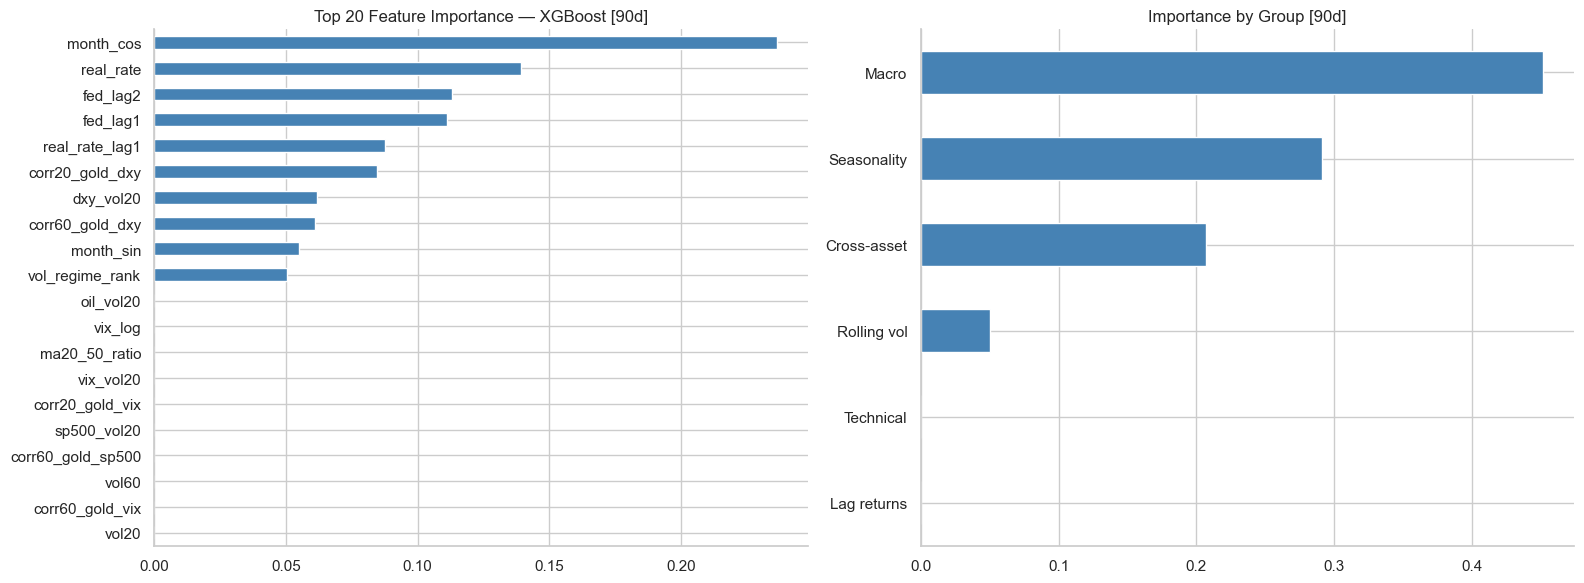

  Smart predict (conf > 0.55): 731 trades  |  acc=81.4%


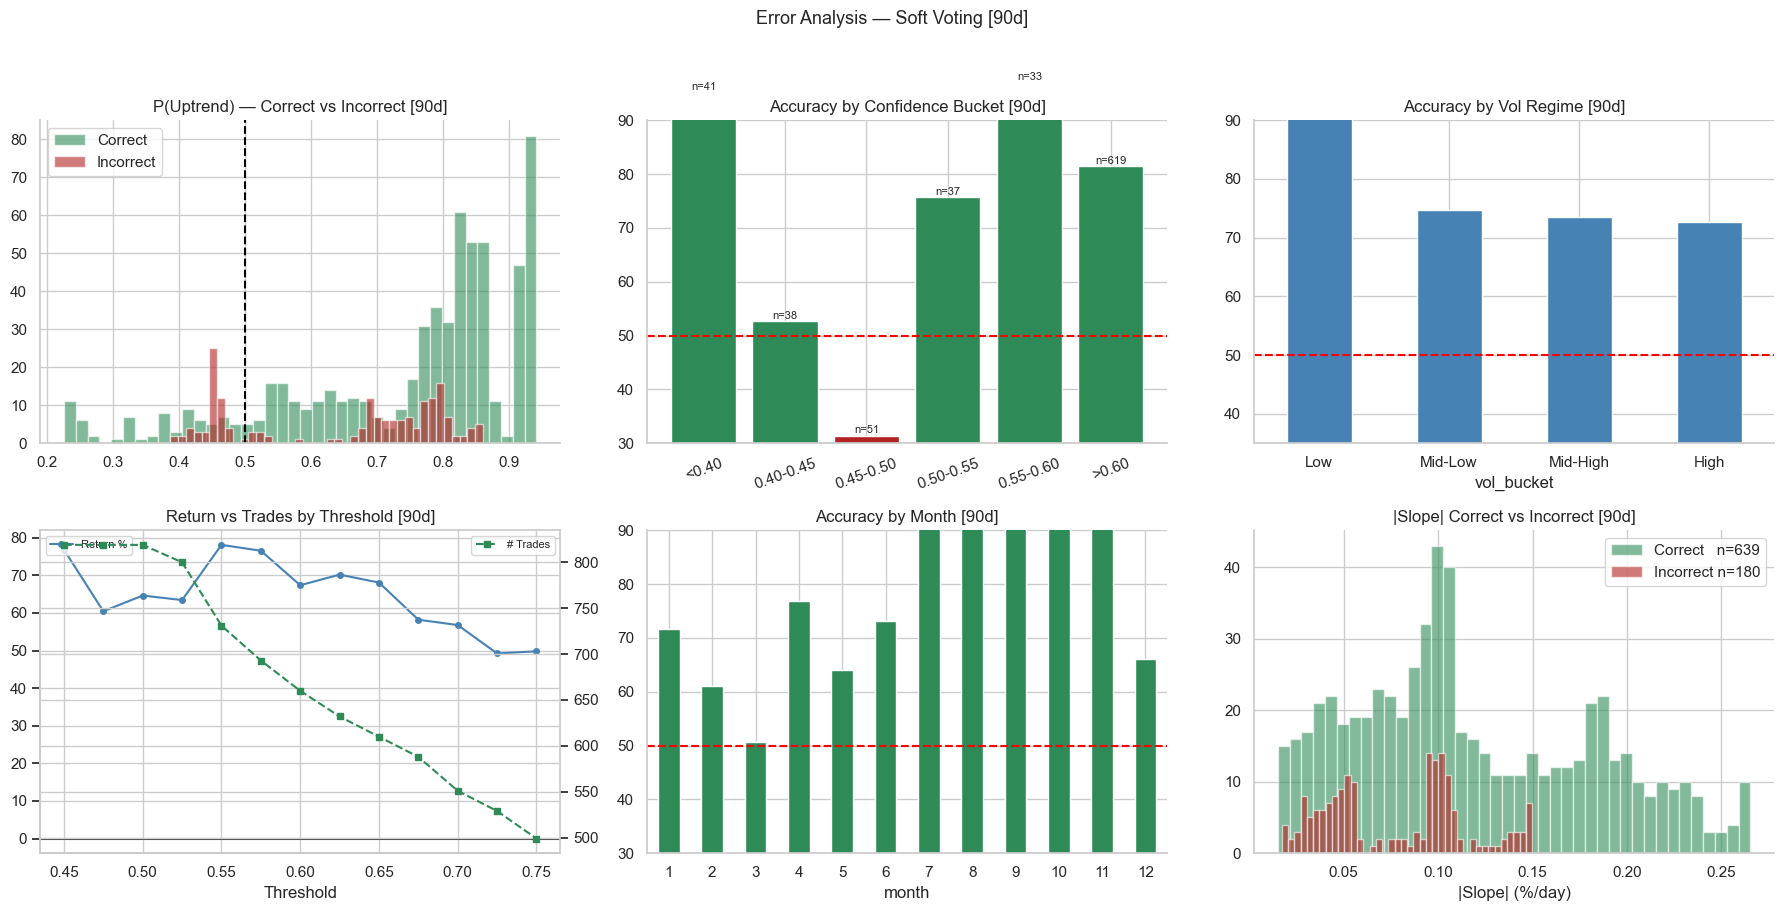


  Feature Importance & Error Analysis — 252d
  Best model: Logistic Regression


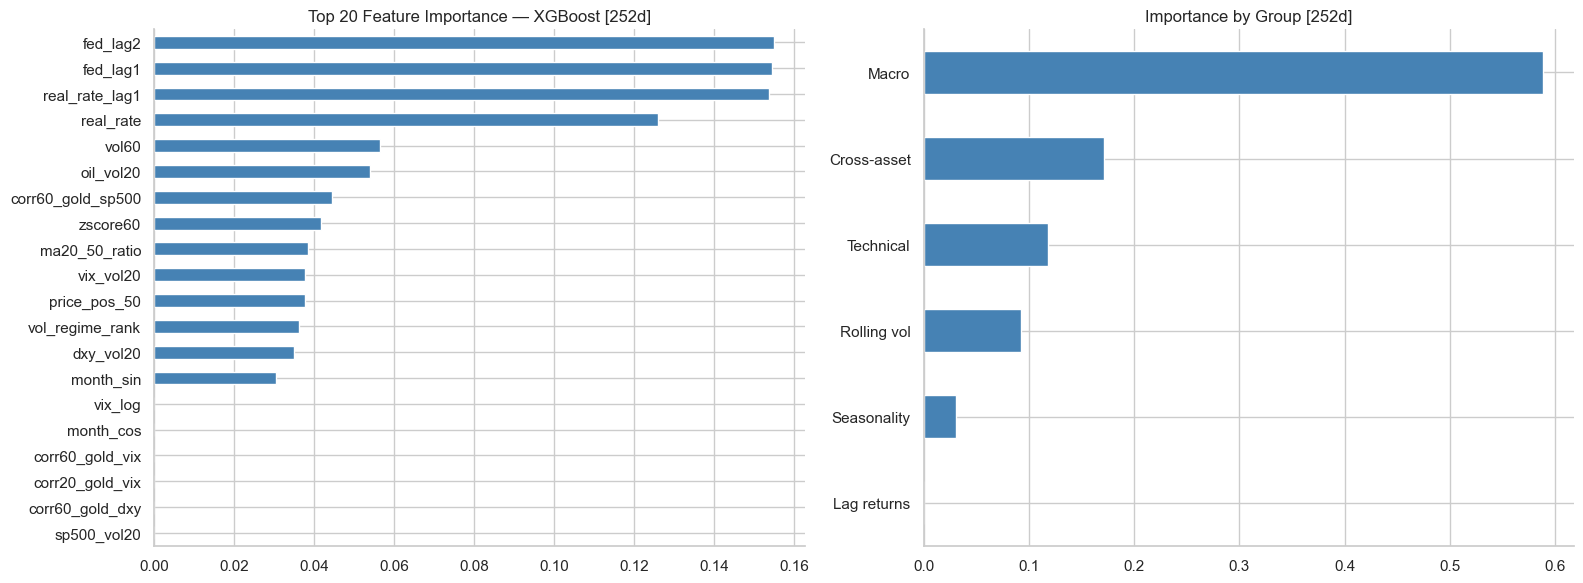

  Smart predict (conf > 0.55): 842 trades  |  acc=98.0%


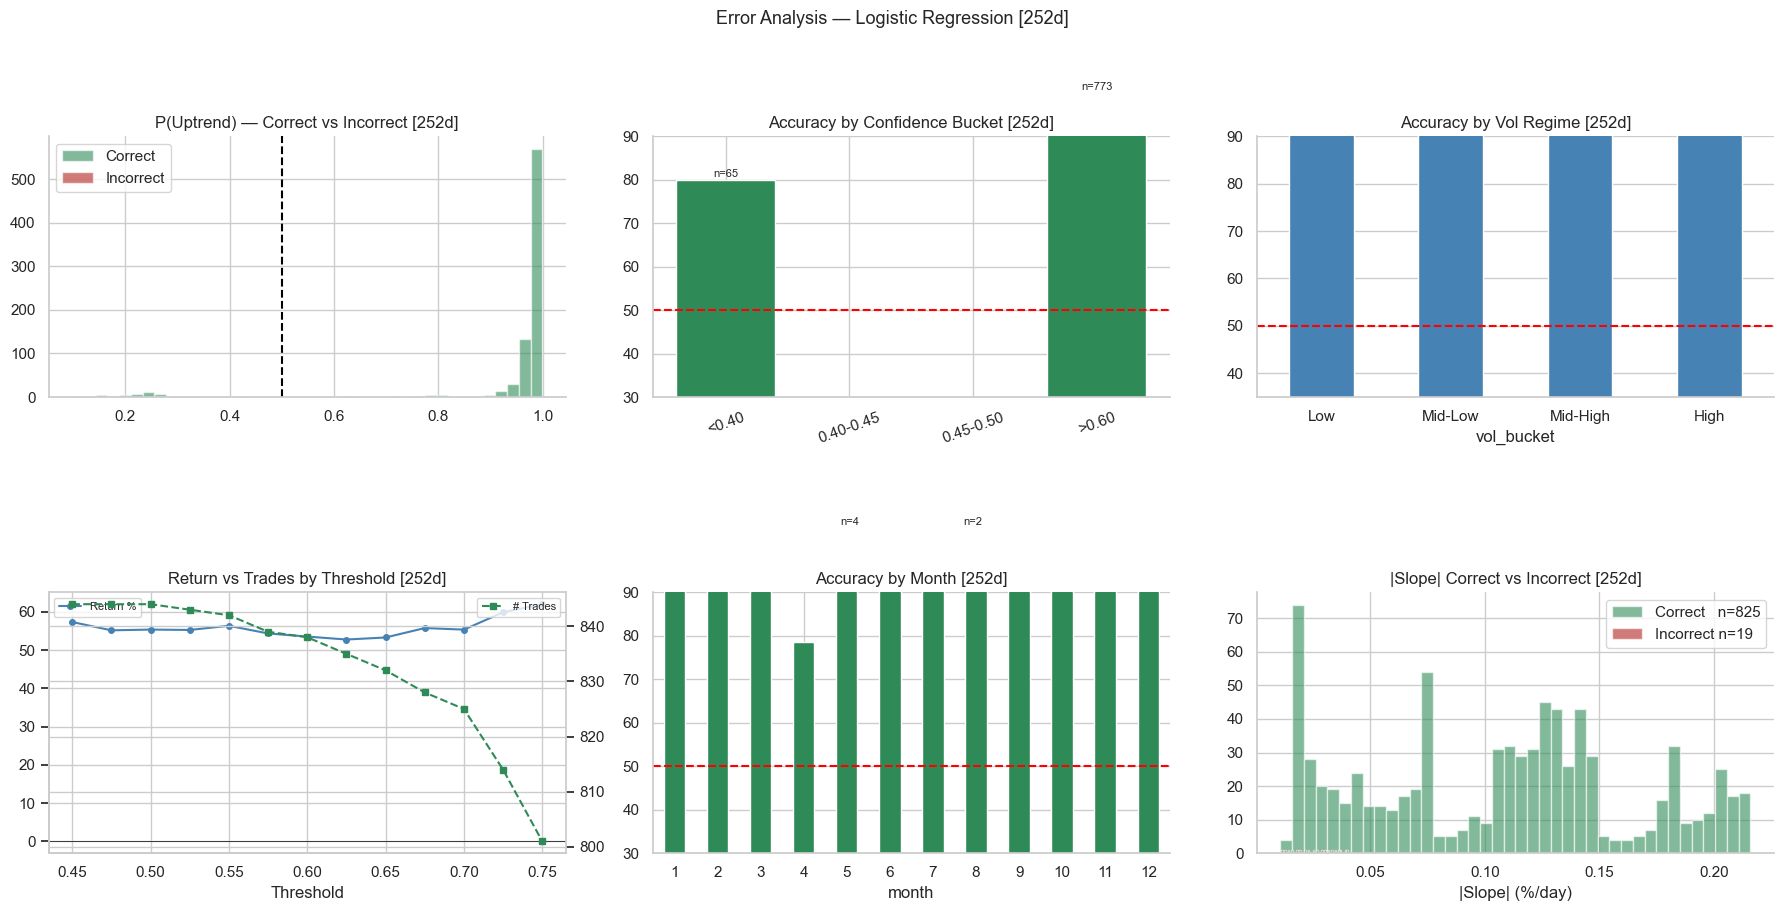

In [19]:
KEY_MAP = {
    "Soft Voting":         "SoftVote",
    "Weighted Voting":     "WeightedVote",
    "Stacking":            "Stack",
    "Logistic Regression": "LR",
    "Random Forest":       "RF",
    "XGBoost":             "XGB",
    "LightGBM":            "LGBM",
}

for HORIZON in [90, 252]:
    s         = setup[HORIZON]
    y_test    = s["y_test"]
    test_df   = s["test_df"]
    xgb_model = all_models[HORIZON]["XGB"]
    feat_sel  = s["feat_sel"]

    best_name = all_results[HORIZON]["auc"].idxmax()
    best_key  = KEY_MAP.get(best_name, best_name)
    best_prob = all_probs[HORIZON][best_key]
    best_pred = (best_prob >= 0.5).astype(int)

    print(f"\n{'='*55}")
    print(f"  Feature Importance & Error Analysis — {HORIZON}d")
    print(f"  Best model: {best_name}")
    print(f"{'='*55}")

    # Feature importance
    fi = pd.Series(xgb_model.feature_importances_,
                   index=feat_sel).sort_values(ascending=False)

    groups = {
        "Lag returns": [f for f in feat_sel if "ret_lag" in f],
        "Rolling vol": [f for f in feat_sel if f.startswith("vol") or "vol_" in f],
        "Technical":   [f for f in feat_sel if any(x in f for x in
                        ["rsi","bb","stoch","roc","ratio","pos","zscore","adx","ret_mean"])],
        "Cross-asset": [f for f in feat_sel if any(x in f for x in
                        ["dxy","sp500","oil","vix","usd_vnd","corr"])],
        "Macro":       [f for f in feat_sel if any(x in f for x in
                        ["cpi","fed","real"])],
        "Seasonality": [f for f in feat_sel if any(x in f for x in
                        ["sin","cos","month","wday","is_month"])],
    }
    group_imp = {k: fi[[f for f in v if f in fi.index]].sum()
                 for k, v in groups.items()}

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fi.head(20).plot(kind="barh", ax=axes[0], color="steelblue", edgecolor="white")
    axes[0].invert_yaxis()
    axes[0].set_title(f"Top 20 Feature Importance — XGBoost [{HORIZON}d]")
    axes[0].spines[["top","right"]].set_visible(False)

    pd.Series(group_imp).sort_values().plot(
        kind="barh", ax=axes[1], color="steelblue", edgecolor="white")
    axes[1].set_title(f"Importance by Group [{HORIZON}d]")
    axes[1].spines[["top","right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

    # Error analysis
    an = test_df.copy().reset_index(drop=True)
    an["y_true"]    = y_test
    an["y_pred"]    = best_pred
    an["y_prob"]    = best_prob
    an["correct"]   = (y_test == best_pred)
    an["abs_slope"] = an[f"slope_{HORIZON}d"].abs()

    mask_hc   = (an["y_prob"] > 0.55) | (an["y_prob"] < 0.45)
    smart_acc = accuracy_score(an.loc[mask_hc,"y_true"],
                               (an.loc[mask_hc,"y_prob"]>0.5).astype(int)) * 100 \
                if mask_hc.sum() > 0 else 0
    print(f"  Smart predict (conf > 0.55): {mask_hc.sum()} trades  |  acc={smart_acc:.1f}%")

    fig, axes = plt.subplots(2, 3, figsize=(18, 9))

    # P(Up) distribution
    axes[0,0].hist(an.loc[an["correct"],  "y_prob"], bins=40,
                   alpha=0.6, color="seagreen",  label="Correct")
    axes[0,0].hist(an.loc[~an["correct"], "y_prob"], bins=40,
                   alpha=0.6, color="firebrick", label="Incorrect")
    axes[0,0].axvline(0.5, color="black", linestyle="--")
    axes[0,0].set_title(f"P(Uptrend) — Correct vs Incorrect [{HORIZON}d]")
    axes[0,0].legend()
    axes[0,0].spines[["top","right"]].set_visible(False)

    # Confidence bucket accuracy
    an["conf_bucket"] = pd.cut(an["y_prob"].clip(0,1),
        bins=[0, 0.4, 0.45, 0.5, 0.55, 0.6, 1.0],
        labels=["<0.40","0.40-0.45","0.45-0.50","0.50-0.55","0.55-0.60",">0.60"])
    ba   = an.groupby("conf_bucket", observed=True)["correct"].mean() * 100
    bn   = an.groupby("conf_bucket", observed=True).size()
    bc   = ["firebrick" if x < 50 else "seagreen" for x in ba]
    bars = axes[0,1].bar(ba.index.astype(str), ba.values, color=bc, edgecolor="white")
    axes[0,1].axhline(50, color="red", linestyle="--")
    for bar, n in zip(bars, bn.values):
        axes[0,1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                       f"n={n}", ha="center", fontsize=8)
    axes[0,1].set_title(f"Accuracy by Confidence Bucket [{HORIZON}d]")
    axes[0,1].set_ylim(30, 90)
    axes[0,1].tick_params(axis="x", rotation=20)
    axes[0,1].spines[["top","right"]].set_visible(False)

    # Accuracy by vol regime
    an["vol_bucket"] = pd.qcut(an["vol20"], q=4,
                                labels=["Low","Mid-Low","Mid-High","High"])
    va = an.groupby("vol_bucket", observed=True)["correct"].mean() * 100
    va.plot(kind="bar", ax=axes[0,2], color="steelblue", edgecolor="white", rot=0)
    axes[0,2].axhline(50, color="red", linestyle="--")
    axes[0,2].set_title(f"Accuracy by Vol Regime [{HORIZON}d]")
    axes[0,2].set_ylim(35, 90)
    axes[0,2].spines[["top","right"]].set_visible(False)

    # Return vs trades by threshold
    an["actual_ret"] = np.log(an["gold"].shift(-1) / an["gold"]).fillna(0)
    thrs = np.arange(0.45, 0.76, 0.025)
    pnl  = []
    for thr in thrs:
        mask = (an["y_prob"] > thr) | (an["y_prob"] < (1-thr))
        pf   = np.where(an["y_prob"] > thr, 1,
               np.where(an["y_prob"] < (1-thr), -1, 0))
        ret  = np.where(pf==1,  an["actual_ret"],
               np.where(pf==-1, -an["actual_ret"], 0))
        pnl.append({"thr": thr, "ret": ret.sum()*100, "n": mask.sum(),
                    "acc": an.loc[mask,"correct"].mean()*100 if mask.sum()>0 else 0})
    pnl_df = pd.DataFrame(pnl)
    ax2r   = axes[1,0].twinx()
    axes[1,0].plot(pnl_df["thr"], pnl_df["ret"],
                   color="steelblue", marker="o", ms=4, label="Return %")
    ax2r.plot(pnl_df["thr"], pnl_df["n"],
              color="seagreen", marker="s", ms=4, linestyle="--", label="# Trades")
    axes[1,0].axhline(0, color="black", linewidth=0.5)
    axes[1,0].set_title(f"Return vs Trades by Threshold [{HORIZON}d]")
    axes[1,0].set_xlabel("Threshold")
    axes[1,0].legend(loc="upper left",  fontsize=8)
    ax2r.legend(loc="upper right", fontsize=8)
    axes[1,0].spines[["top","right"]].set_visible(False)

    # Accuracy by month
    an["month"] = pd.to_datetime(an["date"]).dt.month
    ma  = an.groupby("month")["correct"].mean() * 100
    mc  = ["seagreen" if x >= 50 else "firebrick" for x in ma]
    ma.plot(kind="bar", ax=axes[1,1], color=mc, edgecolor="white", rot=0)
    axes[1,1].axhline(50, color="red", linestyle="--")
    axes[1,1].set_title(f"Accuracy by Month [{HORIZON}d]")
    axes[1,1].set_ylim(30, 90)
    axes[1,1].spines[["top","right"]].set_visible(False)

    # |slope| correct vs incorrect
    axes[1,2].hist(an.loc[an["correct"],  "abs_slope"]*100, bins=40,
                   alpha=0.6, color="seagreen",
                   label=f"Correct   n={an['correct'].sum()}")
    axes[1,2].hist(an.loc[~an["correct"], "abs_slope"]*100, bins=40,
                   alpha=0.6, color="firebrick",
                   label=f"Incorrect n={(~an['correct']).sum()}")
    axes[1,2].set_title(f"|Slope| Correct vs Incorrect [{HORIZON}d]")
    axes[1,2].set_xlabel("|Slope| (%/day)")
    axes[1,2].legend()
    axes[1,2].spines[["top","right"]].set_visible(False)

    plt.suptitle(f"Error Analysis — {best_name} [{HORIZON}d]", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()